In [2]:
# ============================================================
# SESSION CACHE — paste as the FIRST cell of the notebook
# Keeps DataFrames, arrays, and models in memory across cells.
# Persists to /kaggle/working/_cache/ so it survives restarts.
# ============================================================
import os, pickle, hashlib, functools
import pandas as pd

CACHE_DIR = "/kaggle/working/_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# Global in-memory store
_MEM = {}

# Registry of "how to build X if missing"
_BUILDERS = {}   # name -> callable() -> value


def register(name, builder, persist=True):
    """Register a producer. builder() returns the object."""
    _BUILDERS[name] = (builder, persist)


def get(name):
    """Fetch from memory, else disk, else rebuild via registered builder."""
    # 1. memory
    if name in _MEM:
        return _MEM[name]

    # 2. disk
    pkl = os.path.join(CACHE_DIR, f"{name}.pkl")
    parq = os.path.join(CACHE_DIR, f"{name}.parquet")

    if os.path.exists(pkl):
        with open(pkl, "rb") as f:
            obj = pickle.load(f)
        _MEM[name] = obj
        print(f"[cache] loaded {name} from disk (pickle)")
        return obj

    if os.path.exists(parq):
        obj = pd.read_parquet(parq)
        _MEM[name] = obj
        print(f"[cache] loaded {name} from disk (parquet)")
        return obj

    # 3. rebuild
    if name not in _BUILDERS:
        raise KeyError(f"No cached '{name}' and no builder registered.")
    builder, persist = _BUILDERS[name]
    print(f"[cache] building {name} ...")
    obj = builder()
    _MEM[name] = obj

    if persist:
        try:
            if isinstance(obj, pd.DataFrame):
                obj.to_parquet(parq, compression="snappy")
            else:
                with open(pkl, "wb") as f:
                    pickle.dump(obj, f, protocol=4)
            print(f"[cache] saved {name} to disk")
        except Exception as e:
            print(f"[cache] WARN: could not persist {name}: {e}")

    return obj


def ensure_all():
    """Build/load every registered artifact in dependency order."""
    for name in _BUILDERS:
        get(name)
    print(f"[cache] ready: {list(_MEM.keys())}")


def clear_memory():
    _MEM.clear()
    print("[cache] memory cleared (disk kept)")


def clear_disk():
    import shutil
    shutil.rmtree(CACHE_DIR, ignore_errors=True)
    os.makedirs(CACHE_DIR, exist_ok=True)
    print("[cache] disk cleared")

In [3]:
# ---- 1. cleaned_sgcc ----
def _build_cleaned_sgcc():
    RAW = "/kaggle/input/datasets/bensalem14/sgcc-dataset/data set.csv"
    df = pd.read_csv(RAW)
    import numpy as np
    def fix_date(s):
        p = str(s).split("/")
        return f"{int(p[0]):02d}/{int(p[1]):02d}/{p[2]}" if len(p) == 3 else s
    non_date = ["CONS_NO", "FLAG"]
    raw_dates = [c for c in df.columns if c not in non_date]
    df = df.rename(columns={c: fix_date(c) for c in raw_dates})
    date_cols = [fix_date(c) for c in raw_dates]
    parsed = pd.to_datetime(date_cols, format="%m/%d/%Y", errors="coerce")
    order = np.argsort(parsed.values)
    date_cols_sorted = [date_cols[i] for i in order]
    df = df[date_cols_sorted + non_date].set_index("CONS_NO")
    df["missing_count"] = df[date_cols_sorted].isna().sum(axis=1)
    df["missing_ratio"] = df["missing_count"] / len(date_cols_sorted)
    df = df[date_cols_sorted + ["missing_count", "missing_ratio", "FLAG"]]
    print("cleaned_sgcc:", df.shape)
    return df

register("cleaned_sgcc", _build_cleaned_sgcc)


# ---- 2. v4 train/test feature split (split FIRST, no leakage) ----
def _build_v4_features():
    from sklearn.model_selection import train_test_split
    import numpy as np

    df = get("cleaned_sgcc").reset_index()
    date_cols = [c for c in df.columns
                 if c not in ("CONS_NO", "FLAG", "missing_count", "missing_ratio")]
    dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

    idx = np.arange(len(df))
    idx_tr, idx_te, y_tr, y_te = train_test_split(
        idx, df["FLAG"].values, test_size=0.20,
        stratify=df["FLAG"].values, random_state=42
    )

    def max_streak_fn(nan_row):
        a = nan_row.astype(int).values
        if a.sum() == 0: return 0
        d = np.diff(np.concatenate([[0], a, [0]]))
        s = np.where(d == 1)[0]; e = np.where(d == -1)[0]
        return int((e - s).max())

    def build(df_sub):
        F = pd.DataFrame(index=df_sub.index)
        X = df_sub[date_cols]

        F["mean_filled"]   = X.mean(axis=1)
        F["mean_total"]    = X.sum(axis=1) / len(date_cols)
        F["std_filled"]    = X.std(axis=1)
        F["median_filled"] = X.median(axis=1)
        F["max_filled"]    = X.max(axis=1)
        F["min_filled"]    = X.min(axis=1)
        F["q90"]           = X.quantile(0.90, axis=1)
        F["q10"]           = X.quantile(0.10, axis=1)
        F["cv"]            = F["std_filled"] / (F["mean_filled"] + 1e-6)
        F["max_min_ratio"] = F["max_filled"] / (F["min_filled"] + 1e-6)
        F["q90_q10_ratio"] = F["q90"] / (F["q10"] + 1e-6)
        F["coverage_impact"] = F["mean_filled"] - F["mean_total"]

        y2014 = [c for c, d in zip(date_cols, dates) if d.year == 2014]
        y2015 = [c for c, d in zip(date_cols, dates) if d.year == 2015]
        y2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
        peak2016   = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (6,7,8)]
        winter2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (12,1,2)]

        for label, cols in [("2014", y2014), ("2015", y2015), ("2016", y2016),
                            ("peak2016", peak2016), ("winter2016", winter2016)]:
            sub = df_sub[cols]
            F[f"nan_ratio_{label}"]  = sub.isna().mean(axis=1)
            F[f"max_streak_{label}"] = sub.isna().apply(max_streak_fn, axis=1)

        F["continuity_2016"]     = F["max_streak_2016"] / ((F["nan_ratio_2016"] * len(y2016)) + 1)
        F["continuity_peak2016"] = F["max_streak_peak2016"] / ((F["nan_ratio_peak2016"] * len(peak2016)) + 1)
        F["has_nan_2016"]        = (F["nan_ratio_2016"] > 0).astype(int)
        F["has_nan_peak2016"]    = (F["nan_ratio_peak2016"] > 0).astype(int)

        summer   = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (6,7,8)]
        winter   = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (12,1,2)]
        shoulder = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (3,4,5,9,10,11)]
        F["summer_mean_2016"]    = df_sub[summer].mean(axis=1)
        F["winter_mean_2016"]    = df_sub[winter].mean(axis=1)
        F["shoulder_mean_2016"]  = df_sub[shoulder].mean(axis=1)
        F["summer_winter_ratio"] = F["summer_mean_2016"] / (F["winter_mean_2016"] + 1e-6)
        F["shoulder_vs_summer"]  = F["shoulder_mean_2016"] / (F["summer_mean_2016"] + 1e-6)

        X2016 = df_sub[y2016].apply(lambda r: r.fillna(r.mean()), axis=1)
        x_axis = np.arange(len(y2016))
        F["trend_2016"] = X2016.apply(
            lambda r: np.polyfit(x_axis, r.values, 1)[0] if r.notna().any() else 0, axis=1)

        F["zero_ratio_2016"]     = (df_sub[y2016] == 0).mean(axis=1)
        F["low_usage_days_2016"] = (df_sub[y2016] < 1).sum(axis=1)

        # 6 peak-season deltas
        peak_cols = {
            "2014": [c for c,d in zip(date_cols, dates) if d.year==2014 and d.month in (6,7,8)],
            "2015": [c for c,d in zip(date_cols, dates) if d.year==2015 and d.month in (6,7,8)],
            "2016": [c for c,d in zip(date_cols, dates) if d.year==2016 and d.month in (6,7,8)],
        }
        peak_stats = {}
        for yr, cols in peak_cols.items():
            sub = df_sub[cols]; nan_sub = sub.isna()
            peak_stats[yr] = {
                "mean": sub.mean(axis=1),
                "nan_ratio": nan_sub.mean(axis=1),
                "max_streak": nan_sub.apply(max_streak_fn, axis=1),
            }
        for stat in ["mean", "nan_ratio", "max_streak"]:
            if "2014" in peak_stats and "2015" in peak_stats:
                F[f"peak_{stat}_delta_2014_2015"] = peak_stats["2015"][stat] - peak_stats["2014"][stat]
            if "2015" in peak_stats and "2016" in peak_stats:
                F[f"peak_{stat}_delta_2015_2016"] = peak_stats["2016"][stat] - peak_stats["2015"][stat]

        return F.replace([np.inf, -np.inf], np.nan)

    train_df = df.iloc[idx_tr].reset_index(drop=True)
    test_df  = df.iloc[idx_te].reset_index(drop=True)
    F_tr = build(train_df); F_te = build(test_df)
    common = sorted(set(F_tr.columns) & set(F_te.columns))
    F_tr = F_tr[common]; F_te = F_te[common]
    F_tr["FLAG"] = train_df["FLAG"].values
    F_te["FLAG"] = test_df["FLAG"].values
    return {"train": F_tr, "test": F_te, "idx_te": idx_te}

register("v4_features", _build_v4_features)


# ---- 3. Trained LightGBM model + predictions ----
def _build_v4_lgbm():
    import numpy as np, lightgbm as lgb
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score

    feats = get("v4_features")
    train, test = feats["train"], feats["test"]
    feat_cols = [c for c in train.columns if c != "FLAG"]
    X_tr, y_tr = train[feat_cols].values, train["FLAG"].values
    X_te, y_te = test[feat_cols].values,  test["FLAG"].values

    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    params = dict(n_estimators=500, num_leaves=31, learning_rate=0.05,
                  min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                  reg_alpha=0.1, reg_lambda=0.1,
                  scale_pos_weight=spw, n_jobs=-1, random_state=42, verbose=-1)

    X_tr2, X_val, y_tr2, y_val = train_test_split(
        X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=42)

    m_val = lgb.LGBMClassifier(**params); m_val.fit(X_tr2, y_tr2)
    val_prob = m_val.predict_proba(X_val)[:, 1]
    best_f1, best_thr = 0, 0.5
    for thr in np.arange(0.05, 0.95, 0.01):
        f1 = f1_score(y_val, (val_prob >= thr).astype(int))
        if f1 > best_f1: best_f1, best_thr = f1, thr

    m = lgb.LGBMClassifier(**params); m.fit(X_tr, y_tr)
    prob = m.predict_proba(X_te)[:, 1]
    pred = (prob >= best_thr).astype(int)

    return {"model": m, "feat_cols": feat_cols, "threshold": float(best_thr),
            "prob": prob, "pred": pred, "y_true": y_te}

register("v4_lgbm", _build_v4_lgbm)

In [4]:
import pandas as pd
import numpy as np
import os

RAW_PATH    = "/kaggle/input/datasets/bensalem14/sgcc-dataset/data set.csv"
OUT_PARQUET = "/kaggle/working/cleaned_sgcc.parquet"

# ---- 1. Load ----
df = pd.read_csv(RAW_PATH)

# ---- 2. Fix date column names ----
def fix_date(s):
    p = str(s).split("/")
    return f"{int(p[0]):02d}/{int(p[1]):02d}/{p[2]}" if len(p) == 3 else s

non_date = ["CONS_NO", "FLAG"]
date_cols_raw = [c for c in df.columns if c not in non_date]
df = df.rename(columns={c: fix_date(c) for c in date_cols_raw})
date_cols = [fix_date(c) for c in date_cols_raw]

# ---- 3. Parse + sort chronologically ----
parsed = pd.to_datetime(date_cols, format="%m/%d/%Y", errors="coerce")
order  = np.argsort(parsed.values)
date_cols_sorted = [date_cols[i] for i in order]

df = df[date_cols_sorted + non_date]

# ---- 4. CONS_NO -> index ----
df = df.set_index("CONS_NO")

# ---- 5. Add missingness features ----
df["missing_count"] = df[date_cols_sorted].isna().sum(axis=1)
df["missing_ratio"] = df["missing_count"] / len(date_cols_sorted)

# ---- 6. Reorder: dates + engineered + FLAG ----
df = df[date_cols_sorted + ["missing_count", "missing_ratio", "FLAG"]]

# ---- 7. Save ----
df.to_parquet(OUT_PARQUET, compression="snappy")
print("Saved:", OUT_PARQUET)
print("Shape:", df.shape)
print("NaN cells:", int(df[date_cols_sorted].isna().sum().sum()))
print("Theft ratio:", df["FLAG"].mean().round(4))

Saved: /kaggle/working/cleaned_sgcc.parquet
Shape: (42372, 1037)
NaN cells: 11233528
Theft ratio: 0.0853


Loaded: (42372, 1037)
Train: (33897, 1034)  Test: (8475, 1034)
Train theft ratio: 0.0853

Mean usage stats (train):
count    33892.000000
mean        10.123118
std         90.368773
min          0.000000
25%          1.981810
50%          5.731467
75%         10.227410
max      13601.100000
dtype: float64

Overall train theft ratio: 0.0853

--- QUANTILE TAILS ---
Tier                    N users  N theft  Theft ratio    vs base
------------------------------------------------------------------------
Top 1% (highest)            339      153       0.4513      5.29x
Top 3%                     1017      338       0.3324      3.90x
Top 5%                     1695      468       0.2761      3.24x
Top 10%                    3390      724       0.2136      2.50x
Bottom 1%                  1669       28       0.0168      0.20x
Bottom 3%                  1669       28       0.0168      0.20x
Bottom 5%                  1697       28       0.0165      0.19x
Bottom 10%                 3390       68 

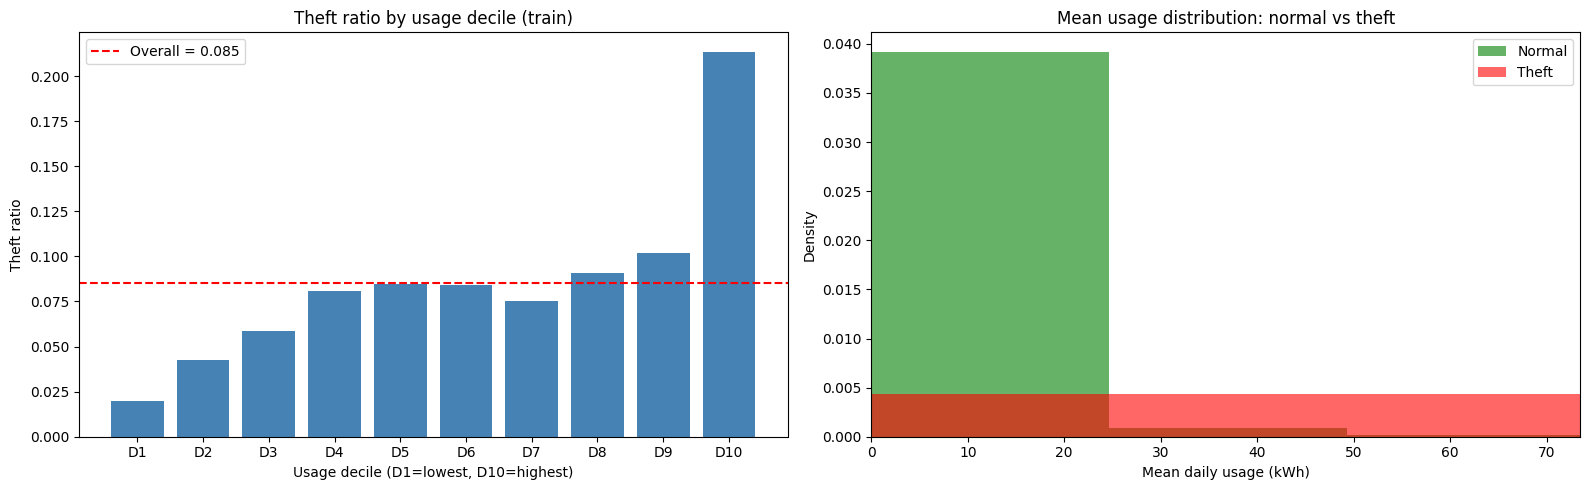


Summary:
       decile  n_users  theft_ratio  lift_vs_base
   D1 (0-10%)     3390     0.020059      0.235111
  D2 (10-20%)     3389     0.042785      0.501487
  D3 (20-30%)     3389     0.058424      0.684789
  D4 (30-40%)     3389     0.080850      0.947637
  D5 (40-50%)     3389     0.084686      0.992598
  D6 (50-60%)     3389     0.084096      0.985681
  D7 (60-70%)     3389     0.075243      0.881925
  D8 (70-80%)     3389     0.090882      1.065227
  D9 (80-90%)     3389     0.101800      1.193192
D10 (90-100%)     3390     0.213569      2.503236

Saved: theft_by_usage_decile.csv + PNG


In [22]:
# ============================================================
# Theft Ratio by Usage Tiers
# EDA on TRAIN split only (no test leakage)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- 1. Load cleaned data ----------
df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
print("Loaded:", df.shape)

consumption_cols = [c for c in df.columns
                    if c not in ("FLAG", "missing_count", "missing_ratio")]

# ---------- 2. Stratified split FIRST ----------
X_all = df[consumption_cols]
y_all = df["FLAG"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)
print(f"Train: {X_tr.shape}  Test: {X_te.shape}")
print(f"Train theft ratio: {y_tr.mean():.4f}")

# ---------- 3. Per-user mean usage (TRAIN only) ----------
mean_usage = X_tr.mean(axis=1)      # NaN-aware by default
print(f"\nMean usage stats (train):")
print(mean_usage.describe())

# ---------- 4. Define tiers ----------
# Quantile-based (equal population per bucket) + fixed thresholds
tiers = {
    "Top 1% (highest)":   mean_usage >= mean_usage.quantile(0.99),
    "Top 3%":             mean_usage >= mean_usage.quantile(0.97),
    "Top 5%":             mean_usage >= mean_usage.quantile(0.95),
    "Top 10%":            mean_usage >= mean_usage.quantile(0.90),
    "Bottom 1%":          mean_usage <= mean_usage.quantile(0.01),
    "Bottom 3%":          mean_usage <= mean_usage.quantile(0.03),
    "Bottom 5%":          mean_usage <= mean_usage.quantile(0.05),
    "Bottom 10%":         mean_usage <= mean_usage.quantile(0.10),
}

# Decile buckets: 0–10%, 10–20%, ..., 90–100% by mean usage
decile_labels = [f"D{i+1} ({i*10}-{(i+1)*10}%)" for i in range(10)]
deciles = pd.qcut(mean_usage, q=10, labels=decile_labels)

# ---------- 5. Report theft ratio per tier ----------
overall_ratio = y_tr.mean()
print(f"\nOverall train theft ratio: {overall_ratio:.4f}")
print("=" * 72)

print("\n--- QUANTILE TAILS ---")
print(f"{'Tier':<22} {'N users':>8} {'N theft':>8} {'Theft ratio':>12} {'vs base':>10}")
print("-" * 72)
for name, mask in tiers.items():
    n = mask.sum()
    if n == 0:
        continue
    theft_n = (y_tr[mask] == 1).sum()
    ratio = theft_n / n
    lift = ratio / overall_ratio
    print(f"{name:<22} {n:>8} {theft_n:>8} {ratio:>12.4f} {lift:>9.2f}x")

print("\n--- DECILE BUCKETS ---")
print(f"{'Decile':<22} {'N users':>8} {'N theft':>8} {'Theft ratio':>12} {'vs base':>10}")
print("-" * 72)
for label in decile_labels:
    mask = deciles == label
    n = mask.sum()
    theft_n = (y_tr[mask] == 1).sum()
    ratio = theft_n / n
    lift = ratio / overall_ratio
    print(f"{label:<22} {n:>8} {theft_n:>8} {ratio:>12.4f} {lift:>9.2f}x")

# ---------- 6. Plot ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Decile theft ratio
decile_ratios = []
decile_sizes  = []
for label in decile_labels:
    mask = deciles == label
    decile_ratios.append((y_tr[mask] == 1).mean())
    decile_sizes.append(mask.sum())

axes[0].bar(range(10), decile_ratios, color="steelblue")
axes[0].axhline(overall_ratio, color="red", linestyle="--",
                label=f"Overall = {overall_ratio:.3f}")
axes[0].set_xticks(range(10))
axes[0].set_xticklabels([f"D{i+1}" for i in range(10)])
axes[0].set_xlabel("Usage decile (D1=lowest, D10=highest)")
axes[0].set_ylabel("Theft ratio")
axes[0].set_title("Theft ratio by usage decile (train)")
axes[0].legend()

# Distribution of mean usage for thieves vs normal
axes[1].hist(mean_usage[y_tr == 0], bins=60, alpha=0.6,
             label="Normal", color="green", density=True)
axes[1].hist(mean_usage[y_tr == 1], bins=60, alpha=0.6,
             label="Theft", color="red", density=True)
axes[1].set_xlabel("Mean daily usage (kWh)")
axes[1].set_ylabel("Density")
axes[1].set_title("Mean usage distribution: normal vs theft")
axes[1].legend()
axes[1].set_xlim(0, mean_usage.quantile(0.99))

plt.tight_layout()
plt.savefig("/kaggle/working/theft_by_usage_tier.png", dpi=100)
plt.show()

# ---------- 7. Summary table for later use ----------
summary = pd.DataFrame({
    "decile": decile_labels,
    "n_users": decile_sizes,
    "theft_ratio": decile_ratios,
})
summary["lift_vs_base"] = summary["theft_ratio"] / overall_ratio
print("\nSummary:")
print(summary.to_string(index=False))

# Save for reference
summary.to_csv("/kaggle/working/theft_by_usage_decile.csv", index=False)
print("\nSaved: theft_by_usage_decile.csv + PNG")

In [18]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd

# ---------- Setup ----------
# Reuse: X_tr, y_tr, mean_usage (from your tier analysis)
# Use ALL train users (or reliable subset — your choice)

date_cols = [c for c in X_tr.columns]  # 1034 date strings
# Parse to datetime for x-axis
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# Assign each user to a decile based on mean_usage
deciles = pd.qcut(mean_usage, q=10, labels=[f"D{i+1}" for i in range(10)])

# ---------- Compute per-decile daily average + NaN count ----------
decile_curves = {}
decile_nan_counts = {}

for d in [f"D{i+1}" for i in range(10)]:
    mask = deciles == d
    sub = X_tr[mask]
    # daily average across users in this decile (NaN-aware)
    decile_curves[d] = sub.mean(axis=0).values
    # daily NaN count across users in this decile
    decile_nan_counts[d] = sub.isna().sum(axis=0).values

# ---------- Build interactive plot ----------
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    row_heights=[0.75, 0.25],
    vertical_spacing=0.05,
    subplot_titles=("Average daily usage by decile (scroll/zoom)",
                    "NaN count per day (all deciles stacked)")
)

colors = ["#d62728", "#ff7f0e", "#bcbd22", "#2ca02c", "#17becf",
          "#1f77b4", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"]

# Top: usage curves per decile
for i, d in enumerate([f"D{i+1}" for i in range(10)]):
    fig.add_trace(
        go.Scatter(
            x=dates, y=decile_curves[d],
            mode="lines",
            name=f"{d} mean usage",
            line=dict(color=colors[i], width=1.5),
            hovertemplate=f"{d}<br>%{{x|%Y-%m-%d}}<br>Usage: %{{y:.2f}}<extra></extra>"
        ),
        row=1, col=1
    )

# Bottom: NaN count per decile (stacked area)
for i, d in enumerate([f"D{i+1}" for i in range(10)]):
    fig.add_trace(
        go.Scatter(
            x=dates, y=decile_nan_counts[d],
            mode="lines",
            name=f"{d} NaN count",
            stackgroup="nan",
            line=dict(color=colors[i], width=0.5),
            hovertemplate=f"{d}<br>%{{x|%Y-%m-%d}}<br>NaN: %{{y}}<extra></extra>",
            showlegend=False
        ),
        row=2, col=1
    )

fig.update_layout(
    height=800,
    title="SGCC: Mean usage by decile over time + NaN counts",
    hovermode="x unified",
    template="plotly_white",
    legend=dict(orientation="h", y=-0.15),
    dragmode="pan"   # default to panning, scroll to zoom
)

fig.update_xaxes(
    rangeslider=dict(visible=True, thickness=0.05),
    row=2, col=1
)
fig.update_yaxes(title_text="Avg usage (kWh)", row=1, col=1)
fig.update_yaxes(title_text="NaN count", row=2, col=1)

fig.show()
fig.write_html("/kaggle/working/decile_usage_scrollable.html")
print("Saved: decile_usage_scrollable.html")

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

Date columns: 1034

NaN STATS: HONEST vs THEFT (raw, no cleaning)

Normal (FLAG=0)  (n=38757)
  NaN count   mean=259.5  median=96  std=297.0  min=1  max=1034
  NaN ratio   mean=0.2510  median=0.0928  std=0.2872
  NaN ratio quantiles: Q10=0.005  Q25=0.013  Q50=0.093  Q75=0.579  Q90=0.706

Theft  (FLAG=1)  (n=3615)
  NaN count   mean=325.4  median=221  std=302.8  min=1  max=1034
  NaN ratio   mean=0.3147  median=0.2137  std=0.2929
  NaN ratio quantiles: Q10=0.006  Q25=0.022  Q50=0.214  Q75=0.706  Q90=0.710

THEFT RATIO BY NaN BUCKET (raw)
NaN ratio bucket      N users  N theft  Theft ratio     Lift
----------------------------------------------------------------------
0%                          0
0-10%                   20997     1375       0.0655    0.77x
10-20%                   4597      378       0.0822    0.96x
20-30%                   2400      310       0.1292    1.51x
30-40%                   1701      187       0.1099    1.29x
40-50%                   1493      159       0.1065

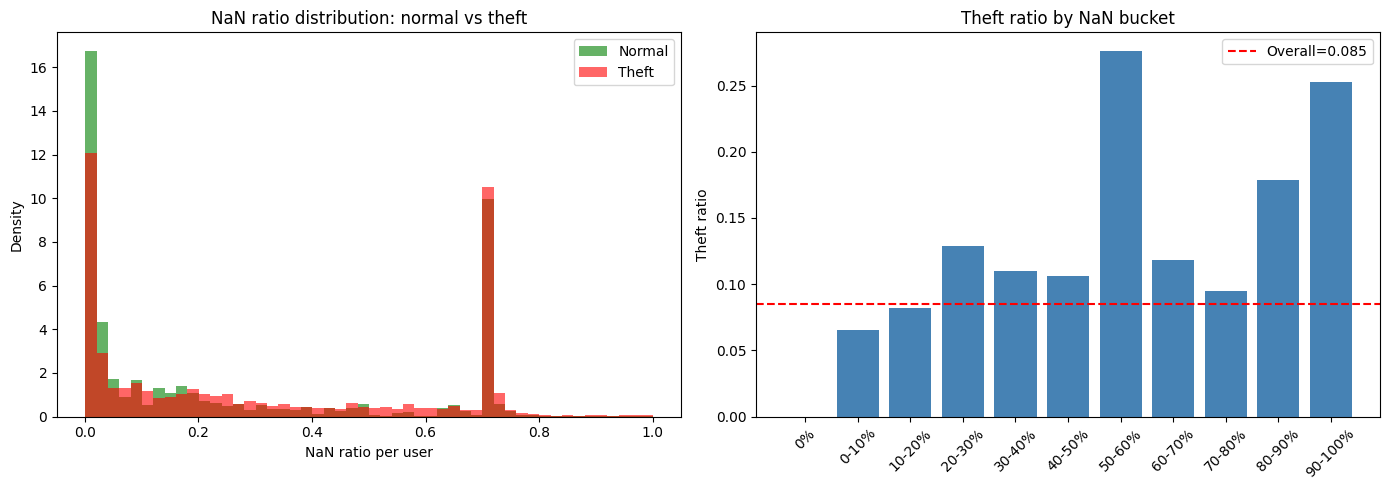

In [13]:
import pandas as pd
import numpy as np

RAW = "/kaggle/input/datasets/bensalem14/sgcc-dataset/data set.csv"
df = pd.read_csv(RAW)

# Identify date columns
non_date = ["CONS_NO", "FLAG"]
date_cols = [c for c in df.columns if c not in non_date]
print(f"Date columns: {len(date_cols)}")

# NaN count + ratio per user
df["nan_count"] = df[date_cols].isna().sum(axis=1)
df["nan_ratio"] = df["nan_count"] / len(date_cols)

# Split by class
normal = df[df["FLAG"] == 0]
theft  = df[df["FLAG"] == 1]

print("\n" + "="*70)
print("NaN STATS: HONEST vs THEFT (raw, no cleaning)")
print("="*70)

for name, sub in [("Normal (FLAG=0)", normal), ("Theft  (FLAG=1)", theft)]:
    nc = sub["nan_count"]
    nr = sub["nan_ratio"]
    print(f"\n{name}  (n={len(sub)})")
    print(f"  NaN count   mean={nc.mean():.1f}  median={nc.median():.0f}  "
          f"std={nc.std():.1f}  min={nc.min()}  max={nc.max()}")
    print(f"  NaN ratio   mean={nr.mean():.4f}  median={nr.median():.4f}  "
          f"std={nr.std():.4f}")
    # Quantiles
    print(f"  NaN ratio quantiles: "
          f"Q10={nr.quantile(0.10):.3f}  Q25={nr.quantile(0.25):.3f}  "
          f"Q50={nr.quantile(0.50):.3f}  Q75={nr.quantile(0.75):.3f}  "
          f"Q90={nr.quantile(0.90):.3f}")

# Buckets of NaN ratio
print("\n" + "="*70)
print("THEFT RATIO BY NaN BUCKET (raw)")
print("="*70)
print(f"{'NaN ratio bucket':<20} {'N users':>8} {'N theft':>8} "
      f"{'Theft ratio':>12} {'Lift':>8}")
print("-"*70)

overall = df["FLAG"].mean()
buckets = [
    ("0%",           df["nan_ratio"] == 0),
    ("0-10%",        (df["nan_ratio"] > 0)    & (df["nan_ratio"] <= 0.10)),
    ("10-20%",       (df["nan_ratio"] > 0.10) & (df["nan_ratio"] <= 0.20)),
    ("20-30%",       (df["nan_ratio"] > 0.20) & (df["nan_ratio"] <= 0.30)),
    ("30-40%",       (df["nan_ratio"] > 0.30) & (df["nan_ratio"] <= 0.40)),
    ("40-50%",       (df["nan_ratio"] > 0.40) & (df["nan_ratio"] <= 0.50)),
    ("50-60%",       (df["nan_ratio"] > 0.50) & (df["nan_ratio"] <= 0.60)),
    ("60-70%",       (df["nan_ratio"] > 0.60) & (df["nan_ratio"] <= 0.70)),
    ("70-80%",       (df["nan_ratio"] > 0.70) & (df["nan_ratio"] <= 0.80)),
    ("80-90%",       (df["nan_ratio"] > 0.80) & (df["nan_ratio"] <= 0.90)),
    ("90-100%",      (df["nan_ratio"] > 0.90)),
]

for label, mask in buckets:
    n = mask.sum()
    if n == 0:
        print(f"{label:<20} {n:>8}")
        continue
    theft_n = (df.loc[mask, "FLAG"] == 1).sum()
    ratio = theft_n / n
    lift = ratio / overall
    print(f"{label:<20} {n:>8} {theft_n:>8} {ratio:>12.4f} {lift:>7.2f}x")

print(f"\nOverall theft ratio: {overall:.4f}")

# ---- Quick plot ----
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of NaN ratio by class
axes[0].hist(normal["nan_ratio"], bins=50, alpha=0.6,
             label="Normal", color="green", density=True)
axes[0].hist(theft["nan_ratio"], bins=50, alpha=0.6,
             label="Theft", color="red", density=True)
axes[0].set_xlabel("NaN ratio per user")
axes[0].set_ylabel("Density")
axes[0].set_title("NaN ratio distribution: normal vs theft")
axes[0].legend()

# Theft ratio vs NaN bucket
labels = [b[0] for b in buckets]
ratios = []
sizes = []
for label, mask in buckets:
    n = mask.sum()
    sizes.append(n)
    ratios.append((df.loc[mask, "FLAG"] == 1).mean() if n else 0)

axes[1].bar(range(len(labels)), ratios, color="steelblue")
axes[1].axhline(overall, color="red", linestyle="--", label=f"Overall={overall:.3f}")
axes[1].set_xticks(range(len(labels)))
axes[1].set_xticklabels(labels, rotation=45)
axes[1].set_ylabel("Theft ratio")
axes[1].set_title("Theft ratio by NaN bucket")
axes[1].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/nan_vs_theft.png", dpi=100)
plt.show()

Old mean (sum/filled):
count    33892.000000
mean        10.123118
std         90.368773
min          0.000000
25%          1.981810
50%          5.731467
75%         10.227410
max      13601.100000
dtype: float64

New mean (sum/total_days):
count    33897.000000
mean         6.951726
std         35.812506
min          0.000000
25%          1.215087
50%          3.719139
75%          7.515716
max       3946.160542
dtype: float64

THEFT RATIO BY DECILE — OLD (sum/filled)
Decile      N users  N theft  Theft ratio     Lift
------------------------------------------------------------
D1             3390       68       0.0201    0.24x
D2             3389      145       0.0428    0.50x
D3             3389      198       0.0584    0.68x
D4             3389      274       0.0808    0.95x
D5             3389      287       0.0847    0.99x
D6             3389      285       0.0841    0.99x
D7             3389      255       0.0752    0.88x
D8             3389      308       0.0909    1.07x
D9   

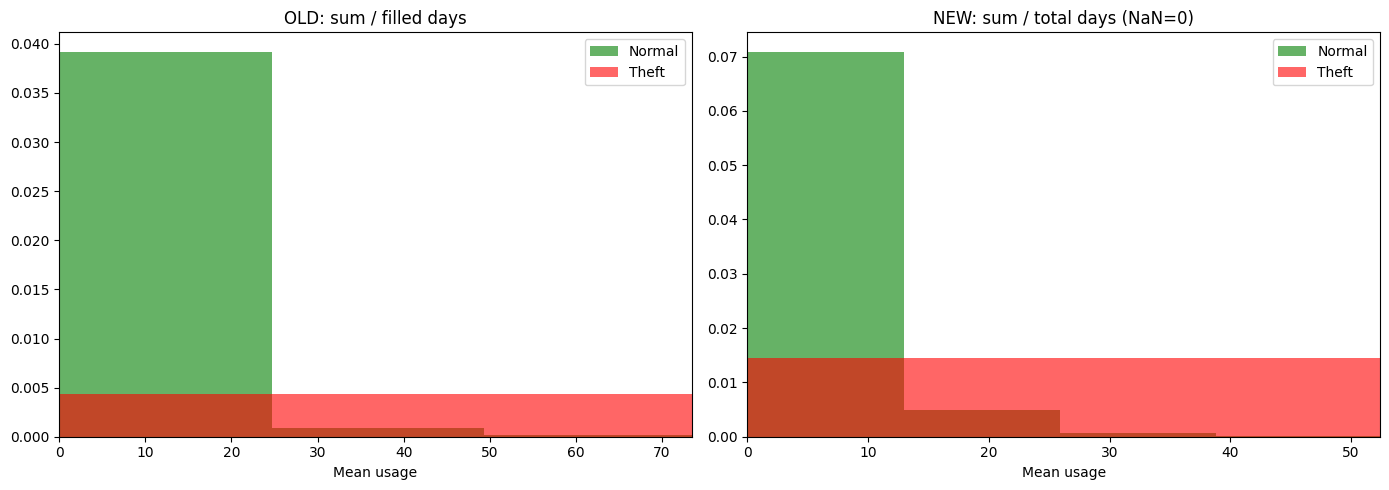

In [14]:
#useful




import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
consumption_cols = [c for c in df.columns
                    if c not in ("FLAG", "missing_count", "missing_ratio")]

X_all, y_all = df[consumption_cols], df["FLAG"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)

total_days = X_tr.shape[1]                     # 1034

# Method 1 (old): sum / filled days (NaN-aware mean)
mean_old = X_tr.mean(axis=1)

# Method 2 (new): sum / total days (NaN counted as 0)
sum_values = X_tr.sum(axis=1, skipna=True)
mean_new = sum_values / total_days

# Compare distributions
print("Old mean (sum/filled):")
print(mean_old.describe())
print("\nNew mean (sum/total_days):")
print(mean_new.describe())

# Decile by each
for label, usage in [("OLD (sum/filled)", mean_old),
                     ("NEW (sum/total_days)", mean_new)]:
    print(f"\n{'='*70}")
    print(f"THEFT RATIO BY DECILE — {label}")
    print("="*70)
    deciles = pd.qcut(usage, q=10, labels=[f"D{i+1}" for i in range(10)])
    overall = y_tr.mean()
    print(f"{'Decile':<10} {'N users':>8} {'N theft':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-"*60)
    for d in [f"D{i+1}" for i in range(10)]:
        mask = deciles == d
        n = mask.sum()
        theft_n = (y_tr[mask] == 1).sum()
        ratio = theft_n / n if n else 0
        print(f"{d:<10} {n:>8} {theft_n:>8} {ratio:>12.4f} {ratio/overall:>7.2f}x")

# Plot comparison
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(mean_old[y_tr==0], bins=60, alpha=0.6, label="Normal", color="green", density=True)
axes[0].hist(mean_old[y_tr==1], bins=60, alpha=0.6, label="Theft", color="red", density=True)
axes[0].set_title("OLD: sum / filled days")
axes[0].set_xlabel("Mean usage")
axes[0].set_xlim(0, mean_old.quantile(0.99))
axes[0].legend()

axes[1].hist(mean_new[y_tr==0], bins=60, alpha=0.6, label="Normal", color="green", density=True)
axes[1].hist(mean_new[y_tr==1], bins=60, alpha=0.6, label="Theft", color="red", density=True)
axes[1].set_title("NEW: sum / total days (NaN=0)")
axes[1].set_xlabel("Mean usage")
axes[1].set_xlim(0, mean_new.quantile(0.99))
axes[1].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/mean_comparison.png", dpi=100)
plt.show()

In [16]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]

# NaN -> 0 so missing days don't distort the total
X0 = df[date_cols].fillna(0)

# Group columns by month
months = pd.to_datetime(date_cols, format="%m/%d/%Y").to_period("M")

# Sum across users per day → then sum per month
daily_total = X0.sum(axis=0)                       # 1034 days
monthly_total = daily_total.groupby(months).sum()  # 34 months

# Also: average per user per month (normalize for user count)
n_users = X0.shape[0]
monthly_avg = monthly_total / n_users

print(monthly_avg.round(2).to_string())

2014-01    146.64
2014-02    119.57
2014-03    153.02
2014-04    139.46
2014-05    154.77
2014-06    179.50
2014-07    259.77
2014-08    228.48
2014-09    216.08
2014-10    168.47
2014-11    151.42
2014-12    171.98
2015-01    178.61
2015-02    154.07
2015-03    163.78
2015-04    149.61
2015-05    155.04
2015-06    192.14
2015-07    199.20
2015-08    186.79
2015-09    143.84
2015-10    131.35
2015-11    123.03
2015-12    135.85
2016-01    294.48
2016-02    269.66
2016-03    285.82
2016-04    259.52
2016-05    286.19
2016-06    343.37
2016-07    412.85
2016-08    400.45
2016-09    285.50
2016-10    278.67
Freq: M


In [18]:
# Users with non-NaN reading per day
coverage = df[date_cols].notna().sum(axis=0)
monthly_coverage = coverage.groupby(months).mean()
print(monthly_coverage.round(0).to_string())

2014-01    25933.0
2014-02    24874.0
2014-03    23994.0
2014-04    24795.0
2014-05    26036.0
2014-06    27303.0
2014-07    28104.0
2014-08    28867.0
2014-09    29819.0
2014-10    28904.0
2014-11    30265.0
2014-12    29943.0
2015-01    29952.0
2015-02    29367.0
2015-03    29058.0
2015-04    28842.0
2015-05    28168.0
2015-06    27610.0
2015-07    27038.0
2015-08    25872.0
2015-09    25707.0
2015-10    25150.0
2015-11    24709.0
2015-12    24147.0
2016-01    41710.0
2016-02    41551.0
2016-03    41754.0
2016-04    41837.0
2016-05    41707.0
2016-06    41768.0
2016-07    41792.0
2016-08    41710.0
2016-09    41360.0
2016-10    41655.0
Freq: M


In [5]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
years = pd.to_datetime(date_cols, format="%m/%d/%Y").year

def streak_stats(nan_row):
    """Return (max_streak, n_streaks, mean_streak) for a boolean NaN row."""
    if not nan_row.any():
        return 0, 0, 0.0
    # Runs of True
    arr = nan_row.values.astype(int)
    diffs = np.diff(np.concatenate([[0], arr, [0]]))
    starts = np.where(diffs == 1)[0]
    ends   = np.where(diffs == -1)[0]
    lengths = ends - starts
    return lengths.max(), len(lengths), lengths.mean()

def analyze_year(cols, label):
    nan_mat = df[cols].isna()
    stats = nan_mat.apply(streak_stats, axis=1)
    df[f"max_streak_{label}"]  = [s[0] for s in stats]
    df[f"n_streaks_{label}"]   = [s[1] for s in stats]
    df[f"mean_streak_{label}"] = [s[2] for s in stats]

    print(f"\n{'='*60}")
    print(f"{label}  ({len(cols)} days)")
    print("="*60)

    # Overall
    print(f"Users with any NaN: {nan_mat.any(axis=1).sum()}")

    # Streak length distribution
    ms = df[f"max_streak_{label}"]
    print(f"\nMax streak length:")
    for q in [0.5, 0.75, 0.90, 0.95, 0.99]:
        print(f"  Q{int(q*100)}: {ms.quantile(q):.0f} days")

    # Bucket by max streak
    print(f"\nTheft ratio by MAX STREAK bucket:")
    print(f"{'Streak':<18} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-"*50)
    overall = df["FLAG"].mean()
    buckets = [
        ("no NaN",     ms == 0),
        ("1-3 days",   (ms > 0)   & (ms <= 3)),
        ("4-7 days",   (ms > 3)   & (ms <= 7)),
        ("8-30 days",  (ms > 7)   & (ms <= 30)),
        ("31-90 days", (ms > 30)  & (ms <= 90)),
        ("91-180 d",   (ms > 90)  & (ms <= 180)),
        (">180 d",     ms > 180),
    ]
    for lab, mask in buckets:
        n = mask.sum()
        if n == 0:
            print(f"{lab:<18} {n:>8}")
            continue
        r = df.loc[mask, "FLAG"].mean()
        print(f"{lab:<18} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

analyze_year([c for c,y in zip(date_cols, years) if y == 2014], "2014")
analyze_year([c for c,y in zip(date_cols, years) if y == 2015], "2015")
analyze_year([c for c,y in zip(date_cols, years) if y == 2016], "2016")


2014  (365 days)
Users with any NaN: 42372

Max streak length:
  Q50: 13 days
  Q75: 280 days
  Q90: 365 days
  Q95: 365 days
  Q99: 365 days

Theft ratio by MAX STREAK bucket:
Streak              N users  Theft ratio     Lift
--------------------------------------------------
no NaN                    0
1-3 days              14848       0.0785    0.92x
4-7 days               4636       0.0500    0.59x
8-30 days              3907       0.0694    0.81x
31-90 days             2222       0.1283    1.50x
91-180 d               3297       0.1140    1.34x
>180 d                13462       0.0955    1.12x

2015  (365 days)
Users with any NaN: 29737

Max streak length:
  Q50: 4 days
  Q75: 365 days
  Q90: 365 days
  Q95: 365 days
  Q99: 365 days

Theft ratio by MAX STREAK bucket:
Streak              N users  Theft ratio     Lift
--------------------------------------------------
no NaN                12635       0.0719    0.84x
1-3 days               8011       0.0615    0.72x
4-7 days       

In [8]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dt = pd.to_datetime(date_cols, format="%m/%d/%Y")

# 2016 columns only
mask_2016 = dt.year == 2016
cols_2016 = [c for c, m in zip(date_cols, mask_2016) if m]
months_2016 = dt[mask_2016].month.values

# High-usage window (summer): Jun-Sep
# Low-usage window (winter): Dec-Feb
summer_mask = np.isin(months_2016, [6,7,8,9])
winter_mask = np.isin(months_2016, [12,1,2])

nan_2016 = df[cols_2016].isna().values
nan_summer = nan_2016[:, summer_mask]
nan_winter = nan_2016[:, winter_mask]

# NaN ratio in each window
df["nan_summer_2016"] = nan_summer.mean(axis=1)
df["nan_winter_2016"] = nan_winter.mean(axis=1)
df["nan_ratio_summer_over_winter"] = (
    (df["nan_summer_2016"] + 1e-6) / (df["nan_winter_2016"] + 1e-6)
)

# ---- Theft ratio by summer NaN bucket ----
print("=" * 60)
print("2016 SUMMER NaN (Jun-Sep) — theft ratio")
print("=" * 60)
overall = df["FLAG"].mean()
print(f"Base theft ratio: {overall:.4f}\n")
print(f"{'Summer NaN':<16} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
print("-" * 50)

buckets = [
    ("0%",         df["nan_summer_2016"] == 0),
    ("0-10%",      (df["nan_summer_2016"] > 0)   & (df["nan_summer_2016"] <= 0.10)),
    ("10-30%",     (df["nan_summer_2016"] > 0.10)& (df["nan_summer_2016"] <= 0.30)),
    ("30-50%",     (df["nan_summer_2016"] > 0.30)& (df["nan_summer_2016"] <= 0.50)),
    ("50-80%",     (df["nan_summer_2016"] > 0.50)& (df["nan_summer_2016"] <= 0.80)),
    (">80%",       df["nan_summer_2016"] > 0.80),
]
for lab, m in buckets:
    n = m.sum()
    if n == 0:
        print(f"{lab:<16} {n:>8}")
        continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<16} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# ---- Same for winter ----
print("\n" + "=" * 60)
print("2016 WINTER NaN (Dec-Feb) — theft ratio")
print("=" * 60)
print(f"{'Winter NaN':<16} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
print("-" * 50)
buckets_w = [
    ("0%",         df["nan_winter_2016"] == 0),
    ("0-10%",      (df["nan_winter_2016"] > 0)   & (df["nan_winter_2016"] <= 0.10)),
    ("10-30%",     (df["nan_winter_2016"] > 0.10)& (df["nan_winter_2016"] <= 0.30)),
    ("30-50%",     (df["nan_winter_2016"] > 0.30)& (df["nan_winter_2016"] <= 0.50)),
    ("50-80%",     (df["nan_winter_2016"] > 0.50)& (df["nan_winter_2016"] <= 0.80)),
    (">80%",       df["nan_winter_2016"] > 0.80),
]
for lab, m in buckets_w:
    n = m.sum()
    if n == 0:
        print(f"{lab:<16} {n:>8}")
        continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<16} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# ---- Ratio: summer NaN vs winter NaN ----
print("\n" + "=" * 60)
print("SUMMER-NaN vs WINTER-NaN ratio — theft ratio")
print("=" * 60)
print(f"{'Ratio':<22} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
print("-" * 55)
buckets_r = [
    ("winter only (=0)",    df["nan_ratio_summer_over_winter"] < 0.1),
    ("both similar (0.5-2)", (df["nan_ratio_summer_over_winter"] >= 0.5) &
                              (df["nan_ratio_summer_over_winter"] <= 2)),
    ("summer 2-10x",         (df["nan_ratio_summer_over_winter"] > 2) &
                              (df["nan_ratio_summer_over_winter"] <= 10)),
    ("summer >10x",          df["nan_ratio_summer_over_winter"] > 10),
]
for lab, m in buckets_r:
    n = m.sum()
    if n == 0:
        print(f"{lab:<22} {n:>8}")
        continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<22} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

2016 SUMMER NaN (Jun-Sep) — theft ratio
Base theft ratio: 0.0853

Summer NaN        N users  Theft ratio     Lift
--------------------------------------------------
0%                  31094       0.0729    0.85x
0-10%                9812       0.1109    1.30x
10-30%               1078       0.1317    1.54x
30-50%                188       0.2287    2.68x
50-80%                 79       0.2025    2.37x
>80%                  121       0.4959    5.81x

2016 WINTER NaN (Dec-Feb) — theft ratio
Winter NaN        N users  Theft ratio     Lift
--------------------------------------------------
0%                  37693       0.0854    1.00x
0-10%                3101       0.0726    0.85x
10-30%                978       0.0573    0.67x
30-50%                212       0.0660    0.77x
50-80%                104       0.2115    2.48x
>80%                  284       0.2746    3.22x

SUMMER-NaN vs WINTER-NaN ratio — theft ratio
Ratio                   N users  Theft ratio     Lift
-------------------

In [9]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dt = pd.to_datetime(date_cols, format="%m/%d/%Y")

# NaN -> 0 for city totals
X0 = df[date_cols].fillna(0)

# Daily city total
daily_total = X0.sum(axis=0)

# Monthly total per year
monthly = daily_total.groupby([dt.year, dt.month]).sum()
print("Monthly city-wide total (NaN=0):")
print(monthly.round(0).to_string())

# Peak months per year (top 3)
print("\nTop 3 peak months per year:")
for year in [2014, 2015, 2016]:
    sub = monthly.loc[year]
    top3 = sub.sort_values(ascending=False).head(3)
    print(f"  {year}: {list(top3.index)}  (values: {list(top3.values.round(0))})")

# Also: per-user average (removes coverage bias)
daily_avg = df[date_cols].mean(axis=0)   # NaN-aware per-user avg
monthly_avg = daily_avg.groupby([dt.year, dt.month]).mean()

print("\nPer-user average monthly usage:")
print(monthly_avg.round(2).to_string())

print("\nTop 3 peak months (per-user avg):")
for year in [2014, 2015, 2016]:
    sub = monthly_avg.loc[year]
    top3 = sub.sort_values(ascending=False).head(3)
    print(f"  {year}: {list(top3.index)}  (values: {list(top3.values.round(2))})")

Monthly city-wide total (NaN=0):
2014  1      6213627.0
      2      5066349.0
      3      6483780.0
      4      5909275.0
      5      6557766.0
      6      7605599.0
      7     11007101.0
      8      9681355.0
      9      9155928.0
      10     7138570.0
      11     6415792.0
      12     7287237.0
2015  1      7567907.0
      2      6528376.0
      3      6939490.0
      4      6339262.0
      5      6569464.0
      6      8141163.0
      7      8440349.0
      8      7914608.0
      9      6094979.0
      10     5565655.0
      11     5212962.0
      12     5756182.0
2016  1     12477654.0
      2     11426224.0
      3     12110636.0
      4     10996260.0
      5     12126610.0
      6     14549254.0
      7     17493138.0
      8     16967982.0
      9     12097146.0
      10    11807830.0

Top 3 peak months per year:
  2014: [7, 8, 9]  (values: [np.float64(11007101.0), np.float64(9681355.0), np.float64(9155928.0)])
  2015: [7, 6, 8]  (values: [np.float64(8440349.0), np.f

In [13]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dt = pd.to_datetime(date_cols, format="%m/%d/%Y")
overall = df["FLAG"].mean()
print(f"Base theft ratio: {overall:.4f}\n")

def max_run(row):
    """Longest consecutive True run in a boolean array."""
    if not row.any():
        return 0
    a = row.astype(int)
    d = np.diff(np.concatenate([[0], a, [0]]))
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return (ends - starts).max()

for year in [2014, 2015, 2016]:
    print("=" * 70)
    print(f"{year} — MAX CONTINUOUS NaN STREAK in peak months (Jun/Jul/Aug)")
    print("=" * 70)

    # Peak-months columns only
    cols_peak = [c for c, d in zip(date_cols, dt)
                 if d.year == year and d.month in (6, 7, 8)]
    if not cols_peak:
        continue
    print(f"Days in window: {len(cols_peak)}")

    nan_mat = df[cols_peak].isna().values
    streaks = np.array([max_run(row) for row in nan_mat])
    df[f"max_streak_peak_{year}"] = streaks

    print(f"\nMax streak distribution:")
    for q in [0.5, 0.75, 0.90, 0.95, 0.99]:
        print(f"  Q{int(q*100)}: {np.quantile(streaks, q):.0f} days")

    print(f"\nTheft ratio by MAX STREAK bucket:")
    print(f"{'Streak':<18} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 50)
    for lab, m in [
        ("no NaN",      streaks == 0),
        ("1-3 days",    (streaks > 0)   & (streaks <= 3)),
        ("4-7 days",    (streaks > 3)   & (streaks <= 7)),
        ("8-30 days",   (streaks > 7)   & (streaks <= 30)),
        ("31-60 days",  (streaks > 30)  & (streaks <= 60)),
        ("61-90 days",  (streaks > 60)  & (streaks <= 90)),
        (">90 days",    streaks > 90),
    ]:
        n = m.sum()
        if n == 0:
            print(f"{lab:<18} {n:>8}")
            continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<18} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")
    print()

Base theft ratio: 0.0853

2014 — MAX CONTINUOUS NaN STREAK in peak months (Jun/Jul/Aug)
Days in window: 92

Max streak distribution:
  Q50: 2 days
  Q75: 92 days
  Q90: 92 days
  Q95: 92 days
  Q99: 92 days

Theft ratio by MAX STREAK bucket:
Streak              N users  Theft ratio     Lift
--------------------------------------------------
no NaN                16382       0.0896    1.05x
1-3 days               7542       0.0549    0.64x
4-7 days               2802       0.0493    0.58x
8-30 days              1884       0.1099    1.29x
31-60 days              788       0.1954    2.29x
61-90 days              573       0.1850    2.17x
>90 days              12401       0.0910    1.07x

2015 — MAX CONTINUOUS NaN STREAK in peak months (Jun/Jul/Aug)
Days in window: 92

Max streak distribution:
  Q50: 2 days
  Q75: 92 days
  Q90: 92 days
  Q95: 92 days
  Q99: 92 days

Theft ratio by MAX STREAK bucket:
Streak              N users  Theft ratio     Lift
----------------------------------------

In [14]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dt = pd.to_datetime(date_cols, format="%m/%d/%Y")

# City-wide daily average (NaN-aware = per-user avg of reporting users)
city_avg = df[date_cols].mean(axis=0)

# For each year, find top 8 weeks (56 days) with highest city average
for year in [2014, 2015, 2016]:
    year_mask = dt.year == year
    year_cols = [c for c, m in zip(date_cols, year_mask) if m]
    if not year_cols:
        continue

    year_avg = city_avg[year_cols]
    # 7-day rolling sum to find "hot weeks"
    year_avg_series = pd.Series(year_avg.values, index=pd.to_datetime(
        [dt[date_cols.index(c)] for c in year_cols]))

    # Top 20% of days by city average = "festival-ish" days
    threshold = year_avg_series.quantile(0.80)
    festival_days = (year_avg_series >= threshold).values

    # Per-user: NaN ratio during festival days vs normal days
    user_nan_fest = df[year_cols].isna().values[:, festival_days].mean(axis=1)
    user_nan_norm = df[year_cols].isna().values[:, ~festival_days].mean(axis=1)

    # Per-user: usage response
    user_mean_fest = df[year_cols].mean(axis=1).values  # placeholder
    # Better: mean over festival columns only
    fest_cols = [c for c, f in zip(year_cols, festival_days) if f]
    norm_cols = [c for c, f in zip(year_cols, festival_days) if not f]

    user_usage_fest = df[fest_cols].mean(axis=1)
    user_usage_norm = df[norm_cols].mean(axis=1)
    response = user_usage_fest / (user_usage_norm + 1e-6)

    overall = df["FLAG"].mean()
    print("=" * 70)
    print(f"{year} — Top 20% usage days (festival-like windows)")
    print("=" * 70)

    # A) NaN during festival days
    print(f"\nNaN ratio during festival days:")
    print(f"{'Bucket':<14} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    for lab, m in [
        ("0%",     user_nan_fest == 0),
        ("0-10%",  (user_nan_fest > 0)   & (user_nan_fest <= 0.10)),
        ("10-30%", (user_nan_fest > 0.10)& (user_nan_fest <= 0.30)),
        ("30-50%", (user_nan_fest > 0.30)& (user_nan_fest <= 0.50)),
        (">50%",   user_nan_fest > 0.50),
    ]:
        n = m.sum()
        if n == 0: continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<14} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

    # B) Usage response: festival / normal
    print(f"\nUsage response (festival avg / normal avg):")
    print(f"{'Ratio':<14} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    for lab, m in [
        ("<0.8 (drops)",  response < 0.8),
        ("0.8-1.0",       (response >= 0.8) & (response < 1.0)),
        ("1.0-1.5",       (response >= 1.0) & (response < 1.5)),
        ("1.5-2.5",       (response >= 1.5) & (response < 2.5)),
        (">2.5 (spikes)", response >= 2.5),
    ]:
        n = m.sum()
        if n == 0: continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<14} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")
    print()

2014 — Top 20% usage days (festival-like windows)

NaN ratio during festival days:
Bucket          N users  Theft ratio     Lift
0%                    9       1.0000   11.72x
0-10%             23572       0.0754    0.88x
10-30%             4831       0.0809    0.95x
30-50%              717       0.1702    1.99x
>50%              13243       0.0993    1.16x

Usage response (festival avg / normal avg):
Ratio           N users  Theft ratio     Lift
<0.8 (drops)       7408       0.0740    0.87x
0.8-1.0            4009       0.0836    0.98x
1.0-1.5           10604       0.0806    0.95x
1.5-2.5            8095       0.0935    1.10x
>2.5 (spikes)      2382       0.0789    0.93x

2015 — Top 20% usage days (festival-like windows)

NaN ratio during festival days:
Bucket          N users  Theft ratio     Lift
0%                19387       0.0714    0.84x
0-10%              6298       0.0614    0.72x
10-30%              850       0.0765    0.90x
30-50%              833       0.0648    0.76x
>50%  

In [19]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# Reliable users only
valid_days = df[date_cols].notna().sum(axis=1)
keep = valid_days >= 300
X = df.loc[keep, date_cols]

# Rolling 20-day median baseline per user
roll_med = X.T.rolling(window=20, min_periods=10, center=True).median().T
roll_med = roll_med.replace(0, np.nan)

# Ratio per (user, day)
ratios = (X / roll_med).clip(upper=10.0)

# Spike flag per (user, day)
SPIKE_THR = 1.5
is_spike = (ratios >= SPIKE_THR)

# Per-day: fraction of users who spiked (only users with valid data that day)
eligible = ratios.notna().sum(axis=0)
spiked   = is_spike.sum(axis=0)
spike_frac = (spiked / eligible.replace(0, np.nan)).fillna(0)

# ---- Top 3 windows per year (10-day window) ----
WINDOW = 10
results = []

for year in [2014, 2015, 2016]:
    year_mask = dates.year == year
    year_idx = np.where(year_mask)[0]
    
    # 10-day rolling average of spike_frac
    frac = spike_frac.values
    win_avg = pd.Series(frac).rolling(window=WINDOW, min_periods=WINDOW).mean().values
    
    # Restrict to this year
    year_win_avg = win_avg.copy()
    year_win_avg[~year_mask] = np.nan
    
    # Greedy pick top 3 non-overlapping windows
    picked = []
    avail = year_win_avg.copy()
    for _ in range(3):
        if np.all(np.isnan(avail)):
            break
        peak = np.nanargmax(avail)
        start = peak - WINDOW + 1
        end   = peak
        picked.append((start, end, avail[peak]))
        # Blank out ±10 days around this window (non-overlap)
        lo = max(0, peak - WINDOW * 2)
        hi = min(len(avail), peak + WINDOW * 2)
        avail[lo:hi] = np.nan
    
    for i, (s, e, avg) in enumerate(picked):
        results.append({
            "year": year,
            "rank": i + 1,
            "start": dates[s].date(),
            "end":   dates[e].date(),
            "avg_spike_frac": round(avg, 3),
            "peak_frac": round(spike_frac.iloc[s:e+1].max(), 3),
        })

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))
res_df.to_csv("/kaggle/working/top3_windows_per_year.csv", index=False)
print("\nSaved: top3_windows_per_year.csv")

 year  rank      start        end  avg_spike_frac  peak_frac
 2014     1 2014-01-23 2014-02-01           0.123      0.257
 2014     2 2014-09-27 2014-10-06           0.120      0.267
 2014     3 2014-02-12 2014-02-21           0.101      0.145
 2015     1 2015-06-25 2015-07-04           0.133      0.225
 2015     2 2015-02-14 2015-02-23           0.121      0.287
 2015     3 2015-08-20 2015-08-29           0.109      0.167
 2016     1 2016-02-01 2016-02-10           0.138      0.323
 2016     2 2016-08-19 2016-08-28           0.114      0.174
 2016     3 2016-05-27 2016-06-05           0.112      0.214

Saved: top3_windows_per_year.csv


In [20]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

windows = [
    ("2014-01-23","2014-02-01"), ("2014-09-27","2014-10-06"),
    ("2014-02-12","2014-02-21"), ("2015-06-25","2015-07-04"),
    ("2015-02-14","2015-02-23"), ("2015-08-20","2015-08-29"),
    ("2016-02-01","2016-02-10"), ("2016-08-19","2016-08-28"),
    ("2016-05-27","2016-06-05"),
]

# Rolling baseline (20-day)
valid_days = df[date_cols].notna().sum(axis=1)
keep = valid_days >= 300
X = df.loc[keep, date_cols]
roll_med = X.T.rolling(20, min_periods=10, center=True).median().T.replace(0, np.nan)
ratios = (X / roll_med).clip(upper=10.0)

# Per user, per window: mean ratio + nan fraction
user_responses = []
user_nan_fest  = []
for s, e in windows:
    ws, we = pd.Timestamp(s), pd.Timestamp(e)
    cols_w = [c for c, d in zip(date_cols, dates) if ws <= d <= we]
    user_resp = ratios[cols_w].mean(axis=1)
    user_nan  = X[cols_w].isna().mean(axis=1)
    user_responses.append(user_resp)
    user_nan_fest.append(user_nan)

resp_df = pd.concat(user_responses, axis=1)
resp_df.columns = [f"w{i+1}" for i in range(len(windows))]
nan_df  = pd.concat(user_nan_fest, axis=1)
nan_df.columns  = [f"w{i+1}" for i in range(len(windows))]

df["festival_resp_mean"] = resp_df.mean(axis=1)
df["festival_resp_min"]  = resp_df.min(axis=1)
df["festival_flat_cnt"]  = (resp_df < 1.2).sum(axis=1)
df["festival_resp_std"]  = resp_df.std(axis=1)
df["festival_nan_mean"]  = nan_df.mean(axis=1)
df["festival_nan_max"]   = nan_df.max(axis=1)

# Theft ratio by festival response
overall = df["FLAG"].mean()
print(f"Base: {overall:.4f}\n")
print("Theft ratio by festival_resp_mean:")
print(f"{'Bucket':<16} {'N':>7} {'Theft':>8} {'Lift':>7}")
for lab, m in [
    ("<0.8",     df["festival_resp_mean"] < 0.8),
    ("0.8-1.0",  (df["festival_resp_mean"] >= 0.8) & (df["festival_resp_mean"] < 1.0)),
    ("1.0-1.2",  (df["festival_resp_mean"] >= 1.0) & (df["festival_resp_mean"] < 1.2)),
    ("1.2-1.5",  (df["festival_resp_mean"] >= 1.2) & (df["festival_resp_mean"] < 1.5)),
    (">1.5",     df["festival_resp_mean"] >= 1.5),
]:
    n = m.sum()
    if n == 0: continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<16} {n:>7} {r:>8.4f} {r/overall:>6.2f}x")

print("\nTheft ratio by festival_nan_mean:")
for lab, m in [
    ("0",        df["festival_nan_mean"] == 0),
    ("0-10%",    (df["festival_nan_mean"] > 0)   & (df["festival_nan_mean"] <= 0.10)),
    ("10-30%",   (df["festival_nan_mean"] > 0.10)& (df["festival_nan_mean"] <= 0.30)),
    ("30-50%",   (df["festival_nan_mean"] > 0.30)& (df["festival_nan_mean"] <= 0.50)),
    (">50%",     df["festival_nan_mean"] > 0.50),
]:
    n = m.sum()
    if n == 0: continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<16} {n:>7} {r:>8.4f} {r/overall:>6.2f}x")

Base: 0.0853

Theft ratio by festival_resp_mean:
Bucket                 N    Theft    Lift
<0.8                 288   0.0590   0.69x
0.8-1.0             4889   0.0812   0.95x
1.0-1.2            23054   0.0927   1.09x
1.2-1.5             5313   0.0785   0.92x
>1.5                3125   0.0787   0.92x

Theft ratio by festival_nan_mean:
0                      9   1.0000  11.72x
0-10%              20590   0.0625   0.73x
10-30%              6929   0.1111   1.30x
30-50%              4495   0.1157   1.36x
>50%                8162   0.0856   1.00x


In [ ]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
print("df shape:", df.shape)
print("df columns (last 5):", list(df.columns[-5:]))

date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")
print("date range:", dates.min(), "->", dates.max())
print("n date cols:", len(date_cols))

valid_days = df[date_cols].notna().sum(axis=1)
keep = valid_days >= 300
print("users kept:", keep.sum())

X = df.loc[keep, date_cols]
print("X shape:", X.shape)

# Rolling median
roll_med = X.T.rolling(20, min_periods=10, center=True).median().T.replace(0, np.nan)
print("roll_med shape:", roll_med.shape)
print("roll_med non-null per user (first 5):", roll_med.notna().sum(axis=1).head().tolist())

ratios = (X / roll_med).clip(upper=10.0)
print("ratios shape:", ratios.shape)
print("ratios non-null total:", ratios.notna().sum().sum())

# Test ONE window
s, e, label = "2014-01-23", "2014-02-01", "SF2014"
ws, we = pd.Timestamp(s), pd.Timestamp(e)
cols_w = [c for c, d in zip(date_cols, dates) if ws <= d <= we]
print(f"\nWindow {label}: cols_w len = {len(cols_w)}")
print("cols_w first 3:", cols_w[:3])

user_resp = ratios[cols_w].mean(axis=1)
print("user_resp non-null:", user_resp.notna().sum())
print("user_resp describe:")
print(user_resp.describe())

city_median = user_resp.median()
print("city_median:", city_median)

relative = user_resp / city_median
print("relative describe:")
print(relative.describe())

# One bucket
m = relative < 0.5
print("bucket <0.5 N:", m.sum())

In [25]:
import pandas as pd, numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet")
df = df.reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")
y = df["FLAG"]
overall = y.mean()
print(f"Base theft ratio: {overall:.4f}\n")

# Only users with decent data
valid_days = df[date_cols].notna().sum(axis=1)
keep = valid_days >= 300
X = df.loc[keep, date_cols]
y_keep = y[keep]

windows = [
    ("2014-01-30","2014-01-31","SF2014"),
    ("2014-10-01","2014-10-03","ND2014"),
    ("2015-02-18","2015-02-19","SF2015"),
    ("2016-02-07","2016-02-08","SF2016"),
    ("2016-10-01","2016-10-03","ND2016"),
]

for s, e, label in windows:
    ws, we = pd.Timestamp(s), pd.Timestamp(e)
    
    # Festival days
    fest_cols = [c for c, d in zip(date_cols, dates) if ws <= d <= we]
    # 3 days before
    base_cols = [c for c, d in zip(date_cols, dates)
                 if ws - pd.Timedelta(days=3) <= d < ws]
    
    if not fest_cols or not base_cols:
        print(f"{label}: missing cols")
        continue
    
    fest_mean = X[fest_cols].mean(axis=1)
    base_mean = X[base_cols].mean(axis=1)
    
    # Avoid /0
    ratio = fest_mean / base_mean.replace(0, np.nan)
    ratio = ratio.clip(upper=10.0)
    
    # Drop users with NaN ratio
    valid = ratio.notna() & base_mean.notna()
    ratio = ratio[valid]
    flags = y_keep[valid]
    
    print("=" * 65)
    print(f"{label}  ({s} to {e})  vs 3 days before  |  N={len(ratio)}  "
          f"city_median={ratio.median():.2f}")
    print("=" * 65)
    print(f"{'Ratio':<14} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 46)
    for lab, m in [
        ("<0.5",     ratio < 0.5),
        ("0.5-0.8",  (ratio >= 0.5) & (ratio < 0.8)),
        ("0.8-1.0",  (ratio >= 0.8) & (ratio < 1.0)),
        ("1.0-1.3",  (ratio >= 1.0) & (ratio < 1.3)),
        ("1.3-2.0",  (ratio >= 1.3) & (ratio < 2.0)),
        ("2.0-3.0",  (ratio >= 2.0) & (ratio < 3.0)),
        (">3.0",     ratio >= 3.0),
    ]:
        n = m.sum()
        if n == 0:
            print(f"{lab:<14} {n:>8}")
            continue
        r = flags[m].mean()
        print(f"{lab:<14} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")
    print()

Base theft ratio: 0.0853

SF2014  (2014-01-30 to 2014-01-31)  vs 3 days before  |  N=19885  city_median=1.02
Ratio           N users  Theft ratio     Lift
----------------------------------------------
<0.5               3608       0.0618    0.72x
0.5-0.8            2638       0.0785    0.92x
0.8-1.0            3157       0.1052    1.23x
1.0-1.3            5147       0.0966    1.13x
1.3-2.0            3661       0.0819    0.96x
2.0-3.0             919       0.0653    0.77x
>3.0                755       0.0583    0.68x

ND2014  (2014-10-01 to 2014-10-03)  vs 3 days before  |  N=25210  city_median=0.94
Ratio           N users  Theft ratio     Lift
----------------------------------------------
<0.5               2464       0.0828    0.97x
0.5-0.8            5391       0.0798    0.93x
0.8-1.0            7522       0.0816    0.96x
1.0-1.3            6268       0.0737    0.86x
1.3-2.0            2552       0.0819    0.96x
2.0-3.0             527       0.0873    1.02x
>3.0                486

In [ ]:
#model





In [23]:
# ============================================================
# SGCC Cleaning — no users dropped, NaN preserved
# Output: /kaggle/working/cleaned_sgcc.parquet
# ============================================================

import pandas as pd
import numpy as np
import os

RAW = "/kaggle/input/datasets/bensalem14/sgcc-dataset/data set.csv"
OUT = "/kaggle/working/cleaned_sgcc.parquet"

df = pd.read_csv(RAW)
print("Raw:", df.shape)

def fix_date(s):
    p = str(s).split("/")
    return f"{int(p[0]):02d}/{int(p[1]):02d}/{p[2]}" if len(p) == 3 else s

non_date = ["CONS_NO", "FLAG"]
date_cols_raw = [c for c in df.columns if c not in non_date]
df = df.rename(columns={c: fix_date(c) for c in date_cols_raw})
date_cols = [fix_date(c) for c in date_cols_raw]

parsed = pd.to_datetime(date_cols, format="%m/%d/%Y", errors="coerce")
order = np.argsort(parsed.values)
date_cols_sorted = [date_cols[i] for i in order]

df = df[date_cols_sorted + non_date]
df = df.set_index("CONS_NO")

# Missing features
df["missing_count"] = df[date_cols_sorted].isna().sum(axis=1)
df["missing_ratio"] = df["missing_count"] / len(date_cols_sorted)

# Keep only date cols + engineered + FLAG
df = df[date_cols_sorted + ["missing_count", "missing_ratio", "FLAG"]]

df.to_parquet(OUT, compression="snappy")
print(f"Cleaned: {df.shape}")
print(f"NaN cells: {int(df[date_cols_sorted].isna().sum().sum())}")
print(f"Theft ratio: {df['FLAG'].mean():.4f}")

Raw: (42372, 1036)
Cleaned: (42372, 1037)
NaN cells: 11233528
Theft ratio: 0.0853


In [24]:
# ============================================================
# SGCC Features — split first, no leakage
# Output: /kaggle/working/features_train.parquet
#         /kaggle/working/features_test.parquet
# ============================================================

import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split

IN = "/kaggle/working/cleaned_sgcc.parquet"
df = pd.read_parquet(IN).reset_index()

date_cols = [c for c in df.columns
             if c not in ("CONS_NO", "FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# ---- SPLIT FIRST ----
idx = np.arange(len(df))
idx_tr, idx_te, y_tr, y_te = train_test_split(
    idx, df["FLAG"].values, test_size=0.20, stratify=df["FLAG"].values, random_state=42
)
print(f"Train: {len(idx_tr)}  Test: {len(idx_te)}")
print(f"Train theft ratio: {y_tr.mean():.4f}  Test theft ratio: {y_te.mean():.4f}")

# ---------- Feature function ----------
def build_features(df_sub, date_cols, dates):
    F = pd.DataFrame(index=df_sub.index)
    X = df_sub[date_cols]

    # ---- usage features ----
    F["mean_filled"]   = X.mean(axis=1)
    F["mean_total"]    = X.sum(axis=1) / len(date_cols)
    F["std_filled"]    = X.std(axis=1)
    F["median_filled"] = X.median(axis=1)
    F["max_filled"]    = X.max(axis=1)
    F["min_filled"]    = X.min(axis=1)
    F["q90"]           = X.quantile(0.90, axis=1)
    F["q10"]           = X.quantile(0.10, axis=1)
    F["cv"]            = F["std_filled"] / (F["mean_filled"] + 1e-6)
    F["max_min_ratio"] = F["max_filled"] / (F["min_filled"] + 1e-6)
    F["q90_q10_ratio"] = F["q90"] / (F["q10"] + 1e-6)
    F["coverage_impact"] = F["mean_filled"] - F["mean_total"]

    # ---- year splits ----
    y2014 = [c for c, d in zip(date_cols, dates) if d.year == 2014]
    y2015 = [c for c, d in zip(date_cols, dates) if d.year == 2015]
    y2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
    peak2016   = [c for c, d in zip(date_cols, dates)
                  if d.year == 2016 and d.month in (6, 7, 8)]
    winter2016 = [c for c, d in zip(date_cols, dates)
                  if d.year == 2016 and d.month in (12, 1, 2)]

    def max_streak(row):
        a = row.astype(int).values
        if a.sum() == 0: return 0
        d = np.diff(np.concatenate([[0], a, [0]]))
        s = np.where(d == 1)[0]; e = np.where(d == -1)[0]
        return int((e - s).max())

    for label, cols in [("2014", y2014), ("2015", y2015), ("2016", y2016),
                        ("peak2016", peak2016), ("winter2016", winter2016)]:
        if not cols: continue
        sub = df_sub[cols]
        F[f"nan_count_{label}"]   = sub.isna().sum(axis=1)
        F[f"nan_ratio_{label}"]   = sub.isna().mean(axis=1)
        F[f"max_streak_{label}"]  = sub.isna().apply(max_streak, axis=1)

    F["continuity_2016"]     = F["max_streak_2016"] / (F["nan_count_2016"] + 1)
    F["continuity_peak2016"] = F["max_streak_peak2016"] / (F["nan_count_peak2016"] + 1)
    F["has_nan_2016"]        = (F["nan_count_2016"] > 0).astype(int)
    F["has_nan_peak2016"]    = (F["nan_count_peak2016"] > 0).astype(int)

    # ---- seasonal ----
    summer   = [c for c, d in zip(date_cols, dates)
                if d.year == 2016 and d.month in (6, 7, 8)]
    winter   = [c for c, d in zip(date_cols, dates)
                if d.year == 2016 and d.month in (12, 1, 2)]
    shoulder = [c for c, d in zip(date_cols, dates)
                if d.year == 2016 and d.month in (3, 4, 5, 9, 10, 11)]
    F["summer_mean_2016"]    = df_sub[summer].mean(axis=1)
    F["winter_mean_2016"]    = df_sub[winter].mean(axis=1)
    F["shoulder_mean_2016"]  = df_sub[shoulder].mean(axis=1)
    F["summer_winter_ratio"] = F["summer_mean_2016"] / (F["winter_mean_2016"] + 1e-6)
    F["shoulder_vs_summer"]  = F["shoulder_mean_2016"] / (F["summer_mean_2016"] + 1e-6)

    # ---- trend ----
    X2016 = df_sub[y2016].apply(lambda r: r.fillna(r.mean()), axis=1)
    x_axis = np.arange(len(y2016))
    F["trend_2016"] = X2016.apply(
        lambda r: np.polyfit(x_axis, r.values, 1)[0] if r.notna().any() else 0, axis=1
    )

    # ---- zero-day ----
    F["zero_days_2016"]      = (df_sub[y2016] == 0).sum(axis=1)
    F["zero_ratio_2016"]     = F["zero_days_2016"] / max(len(y2016), 1)
    F["low_usage_days_2016"] = (df_sub[y2016] < 1).sum(axis=1)

    return F.replace([np.inf, -np.inf], np.nan)


# ---- Build on TRAIN only ----
train_df = df.iloc[idx_tr].reset_index(drop=True)
test_df  = df.iloc[idx_te].reset_index(drop=True)

F_tr = build_features(train_df, date_cols, dates)
F_te = build_features(test_df,  date_cols, dates)

# Align columns
common = sorted(set(F_tr.columns) & set(F_te.columns))
F_tr = F_tr[common]; F_te = F_te[common]

F_tr["FLAG"] = train_df["FLAG"].values
F_te["FLAG"] = test_df["FLAG"].values

F_tr.to_parquet("/kaggle/working/features_train.parquet")
F_te.to_parquet("/kaggle/working/features_test.parquet")

print(f"\nTrain features: {F_tr.shape}  theft ratio: {F_tr['FLAG'].mean():.4f}")
print(f"Test features:  {F_te.shape}  theft ratio: {F_te['FLAG'].mean():.4f}")
print(f"Feature count: {len(common)}")
print(f"NaN in train: {F_tr[common].isna().sum().sum()}")
print(f"NaN in test:  {F_te[common].isna().sum().sum()}")

Train: 33897  Test: 8475
Train theft ratio: 0.0853  Test theft ratio: 0.0853

Train features: (33897, 41)  theft ratio: 0.0853
Test features:  (8475, 41)  theft ratio: 0.0853
Feature count: 40
NaN in train: 703
NaN in test:  141


Features: 40
Train: (33897, 40)  Test: (8475, 40)
Train theft ratio: 0.0853   Test theft ratio: 0.0853
scale_pos_weight: 10.72

LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best threshold: 0.67  (val F1=0.4615)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



--- LightGBM Test ---
F1:        0.4917
Precision: 0.5426
Recall:    0.4495
AUC-ROC:   0.8595
AUC-PR:    0.4960
              precision    recall  f1-score   support

      Normal       0.95      0.96      0.96      7752
       Theft       0.54      0.45      0.49       723

    accuracy                           0.92      8475
   macro avg       0.75      0.71      0.72      8475
weighted avg       0.91      0.92      0.92      8475

[[7478  274]
 [ 398  325]]

XGBoost
Best threshold: 0.61  (val F1=0.4470)

--- XGBoost Test ---
F1:        0.4608
Precision: 0.4583
Recall:    0.4633
AUC-ROC:   0.8486
AUC-PR:    0.4703
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95      7752
       Theft       0.46      0.46      0.46       723

    accuracy                           0.91      8475
   macro avg       0.70      0.71      0.71      8475
weighted avg       0.91      0.91      0.91      8475


SUMMARY
   Model       F1  Precision   Recall 

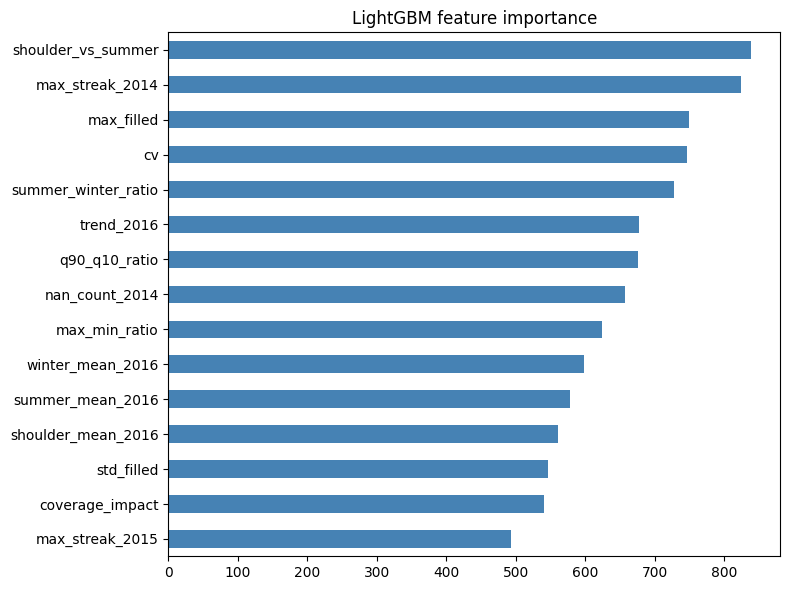

In [25]:
# ============================================================
# SGCC LightGBM + XGBoost
# ============================================================

import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

train = pd.read_parquet("/kaggle/working/features_train.parquet")
test  = pd.read_parquet("/kaggle/working/features_test.parquet")

feat_cols = [c for c in train.columns if c != "FLAG"]
print(f"Features: {len(feat_cols)}")

X_tr = train[feat_cols].values; y_tr = train["FLAG"].values
X_te = test[feat_cols].values;  y_te = test["FLAG"].values

print(f"Train: {X_tr.shape}  Test: {X_te.shape}")
print(f"Train theft ratio: {y_tr.mean():.4f}   Test theft ratio: {y_te.mean():.4f}")

# Imbalance weight
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"scale_pos_weight: {spw:.2f}")

# Threshold-tuning split
X_tr2, X_val, y_tr2, y_val = train_test_split(
    X_tr, y_tr, test_size=0.20, stratify=y_tr, random_state=42
)

# ============================================================
# LightGBM
# ============================================================
print("\n" + "="*60)
print("LightGBM")
print("="*60)

params_lgb = dict(
    n_estimators=500, num_leaves=31, max_depth=-1,
    learning_rate=0.05, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1,
    scale_pos_weight=spw, n_jobs=-1, random_state=42, verbose=-1,
)

# Fit for threshold tuning
m_lgb_val = lgb.LGBMClassifier(**params_lgb)
m_lgb_val.fit(X_tr2, y_tr2)
val_prob = m_lgb_val.predict_proba(X_val)[:, 1]

best_f1, best_thr = 0, 0.5
for thr in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(y_val, (val_prob >= thr).astype(int))
    if f1 > best_f1:
        best_f1, best_thr = f1, thr
print(f"Best threshold: {best_thr:.2f}  (val F1={best_f1:.4f})")

# Fit on full train, test
m_lgb = lgb.LGBMClassifier(**params_lgb)
m_lgb.fit(X_tr, y_tr)
prob_lgb = m_lgb.predict_proba(X_te)[:, 1]
pred_lgb = (prob_lgb >= best_thr).astype(int)

print("\n--- LightGBM Test ---")
print(f"F1:        {f1_score(y_te, pred_lgb):.4f}")
print(f"Precision: {precision_score(y_te, pred_lgb):.4f}")
print(f"Recall:    {recall_score(y_te, pred_lgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_te, prob_lgb):.4f}")
print(f"AUC-PR:    {average_precision_score(y_te, prob_lgb):.4f}")
print(classification_report(y_te, pred_lgb, target_names=["Normal", "Theft"]))
print(confusion_matrix(y_te, pred_lgb))

# ============================================================
# XGBoost
# ============================================================
print("\n" + "="*60)
print("XGBoost")
print("="*60)

params_xgb = dict(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0,
    scale_pos_weight=spw, tree_method="hist",
    n_jobs=-1, random_state=42, eval_metric="aucpr",
)

m_xgb_val = xgb.XGBClassifier(**params_xgb)
m_xgb_val.fit(X_tr2, y_tr2)
val_prob_x = m_xgb_val.predict_proba(X_val)[:, 1]

best_f1_x, best_thr_x = 0, 0.5
for thr in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(y_val, (val_prob_x >= thr).astype(int))
    if f1 > best_f1_x:
        best_f1_x, best_thr_x = f1, thr
print(f"Best threshold: {best_thr_x:.2f}  (val F1={best_f1_x:.4f})")

m_xgb = xgb.XGBClassifier(**params_xgb)
m_xgb.fit(X_tr, y_tr)
prob_xgb = m_xgb.predict_proba(X_te)[:, 1]
pred_xgb = (prob_xgb >= best_thr_x).astype(int)

print("\n--- XGBoost Test ---")
print(f"F1:        {f1_score(y_te, pred_xgb):.4f}")
print(f"Precision: {precision_score(y_te, pred_xgb):.4f}")
print(f"Recall:    {recall_score(y_te, pred_xgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_te, prob_xgb):.4f}")
print(f"AUC-PR:    {average_precision_score(y_te, prob_xgb):.4f}")
print(classification_report(y_te, pred_xgb, target_names=["Normal", "Theft"]))

# ============================================================
# Summary
# ============================================================
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
summary = pd.DataFrame({
    "Model":     ["LightGBM", "XGBoost"],
    "F1":        [f1_score(y_te, pred_lgb), f1_score(y_te, pred_xgb)],
    "Precision": [precision_score(y_te, pred_lgb), precision_score(y_te, pred_xgb)],
    "Recall":    [recall_score(y_te, pred_lgb), recall_score(y_te, pred_xgb)],
    "AUC-PR":    [average_precision_score(y_te, prob_lgb),
                  average_precision_score(y_te, prob_xgb)],
    "Threshold": [best_thr, best_thr_x],
})
print(summary.to_string(index=False))

# Save predictions
pd.DataFrame({
    "y_true": y_te, "prob_lgb": prob_lgb, "prob_xgb": prob_xgb,
    "pred_lgb": pred_lgb, "pred_xgb": pred_xgb,
}).to_parquet("/kaggle/working/test_predictions.parquet")

# Feature importance
imp = pd.Series(m_lgb.feature_importances_, index=feat_cols).sort_values(ascending=False)
print("\nTop 15 LightGBM features:")
print(imp.head(15).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
imp.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_title("LightGBM feature importance")
plt.tight_layout()
plt.savefig("/kaggle/working/feature_importance.png", dpi=100)
plt.show()

In [ ]:
import pandas as pd, numpy as np

train = pd.read_parquet("/kaggle/working/features_train.parquet")
feat_cols = [c for c in train.columns if c != "FLAG"]

# Correlation matrix on features
corr = train[feat_cols].corr().abs()

# List pairs with corr > 0.8
print("Highly correlated feature pairs (|r| > 0.8):")
for i in range(len(feat_cols)):
    for j in range(i + 1, len(feat_cols)):
        if corr.iloc[i, j] > 0.8:
            print(f"  {feat_cols[i]:25s} -- {feat_cols[j]:25s}  r={corr.iloc[i,j]:.3f}")

# Group by family
print("\nFeature count by family:")
for family in ["nan_count", "nan_ratio", "max_streak", "continuity"]:
    cols = [c for c in feat_cols if c.startswith(family)]
    print(f"  {family:15s} {len(cols)} columns: {cols}")

Group counts:
group
TN    7478
FN     398
TP     325
FP     274

Recall (caught / total thieves):  325 / 723 = 0.4495
Precision (real thief / flagged): 325 / 599 = 0.5426

FEATURE MEANS BY GROUP
       mean_filled  mean_total  max_filled  std_filled     cv  max_streak_2014  max_streak_2015  max_streak_2016  nan_ratio_2016  nan_ratio_peak2016  nan_ratio_winter2016  max_streak_peak2016  continuity_2016  summer_winter_ratio  shoulder_vs_summer  trend_2016  zero_ratio_2016  coverage_impact  q90_q10_ratio  max_min_ratio
group                                                                                                                                                                                                                                                                                                                                
FN          10.838       7.001      72.415       7.516  1.079          155.462          159.781            4.367           0.018               0.014     

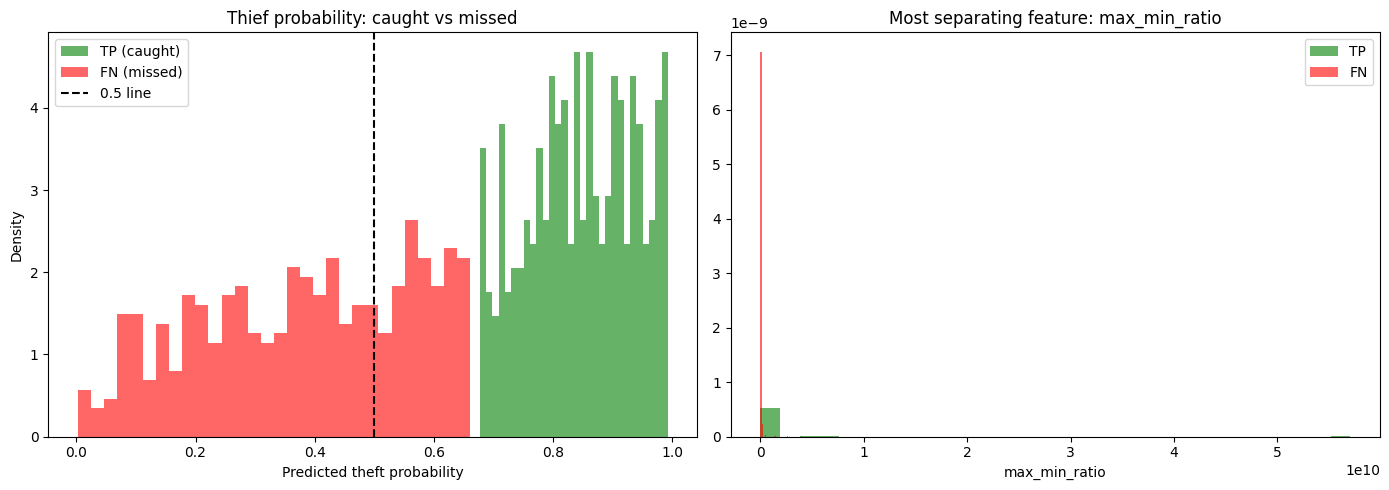


Common signatures of MISSED thieves
Signature                          FN %     TP %        Δ
------------------------------------------------------------
Low NaN 2016 (<10%)               0.955    0.895   +0.059
No NaN 2016                       0.558    0.400   +0.158
Short streak 2016 (<7 days)       0.912    0.751   +0.161
Low usage (bottom half)           0.613    0.360   +0.253
High usage (top half)             0.384    0.640   -0.256
Zero missing peak 2016            0.829    0.809   +0.020
Low volatility (CV < 1)           0.729    0.717   +0.012
Strong summer response            0.312    0.431   -0.119

Saved 398 missed thieves to missed_thieves.csv


In [12]:
# ============================================================
# Error Analysis — what's different about missed thieves?
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load test features + predictions
test  = pd.read_parquet("/kaggle/working/features_test.parquet").reset_index(drop=True)
preds = pd.read_parquet("/kaggle/working/test_predictions.parquet").reset_index(drop=True)

feat_cols = [c for c in test.columns if c != "FLAG"]

# Combine
df = test.copy()
df["prob"]  = preds["prob_lgb"].values
df["pred"]  = preds["pred_lgb"].values
df["y"]     = preds["y_true"].values

# Assign groups
df["group"] = "TN"
df.loc[(df.y==1) & (df.pred==1), "group"] = "TP"
df.loc[(df.y==1) & (df.pred==0), "group"] = "FN"
df.loc[(df.y==0) & (df.pred==1), "group"] = "FP"

print("Group counts:")
print(df["group"].value_counts().to_string())
print(f"\nRecall (caught / total thieves):  {(df.group=='TP').sum()} / {(df.y==1).sum()} "
      f"= {(df.group=='TP').sum()/(df.y==1).sum():.4f}")
print(f"Precision (real thief / flagged): {(df.group=='TP').sum()} / {(df.pred==1).sum()} "
      f"= {(df.group=='TP').sum()/(df.pred==1).sum():.4f}")

# ---- Feature means by group ----
key_feats = [
    "mean_filled", "mean_total", "max_filled", "std_filled", "cv",
    "max_streak_2014", "max_streak_2015", "max_streak_2016",
    "nan_ratio_2016", "nan_ratio_peak2016", "nan_ratio_winter2016",
    "max_streak_peak2016", "continuity_2016",
    "summer_winter_ratio", "shoulder_vs_summer",
    "trend_2016", "zero_ratio_2016", "coverage_impact",
    "q90_q10_ratio", "max_min_ratio",
]

# Only keep features that exist
key_feats = [f for f in key_feats if f in df.columns]

print("\n" + "="*100)
print("FEATURE MEANS BY GROUP")
print("="*100)
summary = df.groupby("group")[key_feats].mean().round(3)
print(summary.to_string())

# ---- FN vs TP comparison ----
print("\n" + "="*100)
print("FN vs TP — what's different about MISSED thieves?")
print("="*100)
thieves = df[df.y == 1]
comp = thieves.groupby("group")[key_feats].mean().round(3)
comp["diff_TP_minus_FN"] = (comp.loc["TP"] - comp.loc["FN"]).round(3)
comp["pct_diff"] = (100 * comp["diff_TP_minus_FN"] / (comp.loc["FN"] + 1e-6)).round(1)
print(comp.to_string())

# ---- Probability distribution ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: thief probability histogram (TP vs FN)
ax = axes[0]
ax.hist(thieves.loc[thieves.group=="TP", "prob"], bins=30, alpha=0.6,
        label="TP (caught)", color="green", density=True)
ax.hist(thieves.loc[thieves.group=="FN", "prob"], bins=30, alpha=0.6,
        label="FN (missed)", color="red", density=True)
ax.axvline(0.5, color="black", linestyle="--", label="0.5 line")
ax.set_xlabel("Predicted theft probability")
ax.set_ylabel("Density")
ax.set_title("Thief probability: caught vs missed")
ax.legend()

# Right: top feature where FN differs most
ax = axes[1]
# Rank features by absolute difference
diff = (comp.loc["TP"] - comp.loc["FN"]).abs().sort_values(ascending=False)
top_feat = diff.index[0]
for g, color in [("TP", "green"), ("FN", "red")]:
    vals = thieves.loc[thieves.group==g, top_feat].dropna()
    ax.hist(vals, bins=30, alpha=0.6, label=g, color=color, density=True)
ax.set_title(f"Most separating feature: {top_feat}")
ax.set_xlabel(top_feat)
ax.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/error_analysis.png", dpi=100)
plt.show()

# ---- Rule hunt: how many FN look "clean" ----
print("\n" + "="*100)
print("Common signatures of MISSED thieves")
print("="*100)
fn = thieves[thieves.group == "FN"]
tp = thieves[thieves.group == "TP"]

checks = {
    "Low NaN 2016 (<10%)":         ("nan_ratio_2016", 0.10, "less"),
    "No NaN 2016":                  ("nan_ratio_2016", 0.0, "equal"),
    "Short streak 2016 (<7 days)":  ("max_streak_2016", 7, "less"),
    "Low usage (bottom half)":      ("mean_filled", None, "median"),
    "High usage (top half)":        ("mean_filled", None, "median_top"),
    "Zero missing peak 2016":       ("nan_ratio_peak2016", 0.0, "equal"),
    "Low volatility (CV < 1)":      ("cv", 1.0, "less"),
    "Strong summer response":       ("summer_winter_ratio", 1.5, "greater"),
}

print(f"{'Signature':<30} {'FN %':>8} {'TP %':>8} {'Δ':>8}")
print("-" * 60)
for label, (feat, val, mode) in checks.items():
    if feat not in thieves.columns:
        continue
    if mode == "less":
        fn_pct = (fn[feat] < val).mean()
        tp_pct = (tp[feat] < val).mean()
    elif mode == "greater":
        fn_pct = (fn[feat] > val).mean()
        tp_pct = (tp[feat] > val).mean()
    elif mode == "equal":
        fn_pct = (fn[feat] == val).mean()
        tp_pct = (tp[feat] == val).mean()
    elif mode == "median":
        med = thieves[feat].median()
        fn_pct = (fn[feat] < med).mean()
        tp_pct = (tp[feat] < med).mean()
    elif mode == "median_top":
        med = thieves[feat].median()
        fn_pct = (fn[feat] > med).mean()
        tp_pct = (tp[feat] > med).mean()
    print(f"{label:<30} {fn_pct:>8.3f} {tp_pct:>8.3f} {fn_pct - tp_pct:>+8.3f}")

# ---- Save FN users for inspection ----
fn_users = df[df.group == "FN"][key_feats + ["prob"]].copy()
fn_users.to_csv("/kaggle/working/missed_thieves.csv", index=False)
print(f"\nSaved {len(fn_users)} missed thieves to missed_thieves.csv")

In [14]:
import pandas as pd
import numpy as np

test  = pd.read_parquet("/kaggle/working/features_test.parquet").reset_index(drop=True)
preds = pd.read_parquet("/kaggle/working/test_predictions.parquet").reset_index(drop=True)

df = test.copy()
df["prob"] = preds["prob_lgb"].values
df["pred"] = preds["pred_lgb"].values
df["y"]    = preds["y_true"].values

df["group"] = "TN"
df.loc[(df.y==1) & (df.pred==1), "group"] = "TP"
df.loc[(df.y==1) & (df.pred==0), "group"] = "FN"
df.loc[(df.y==0) & (df.pred==1), "group"] = "FP"

feat_cols = [c for c in test.columns if c != "FLAG"]

fp = df[df.group=="FP"]
tp = df[df.group=="TP"]
tn = df[df.group=="TN"]
fn = df[df.group=="FN"]

print(f"Group sizes: TP={len(tp)}  FP={len(fp)}  FN={len(fn)}  TN={len(tn)}\n")

# Scalars via dicts
fp_means = {f: float(fp[f].mean()) for f in feat_cols}
tp_means = {f: float(tp[f].mean()) for f in feat_cols}
tn_means = {f: float(tn[f].mean()) for f in feat_cols}
fn_means = {f: float(fn[f].mean()) for f in feat_cols}

# ---- Rank by |FP - TN| ----
ranked = sorted(feat_cols, key=lambda f: abs(fp_means[f] - tn_means[f]), reverse=True)

print("="*100)
print(f"{'Feature':<28} {'FP':>10} {'TP':>10} {'TN':>10} {'FP-TN':>10} {'FP-TP':>10}")
print("="*100)
for f in ranked[:20]:
    print(f"{f:<28} {fp_means[f]:>10.3f} {tp_means[f]:>10.3f} "
          f"{tn_means[f]:>10.3f} {fp_means[f]-tn_means[f]:>+10.3f} "
          f"{fp_means[f]-tp_means[f]:>+10.3f}")

# ---- Signature fractions ----
def frac(subset, cond):
    return float(cond(subset).mean())

checks = [
    ("Mean usage > 20",         lambda d: d["mean_filled"] > 20),
    ("Max usage > 100",         lambda d: d["max_filled"] > 100),
    ("Any NaN 2016",            lambda d: d["nan_ratio_2016"] > 0),
    ("NaN 2016 > 5%",           lambda d: d["nan_ratio_2016"] > 0.05),
    ("Long streak 2016 > 14",   lambda d: d["max_streak_2016"] > 14),
    ("Long streak 2014 > 90",   lambda d: d["max_streak_2014"] > 90),
    ("CV > 2",                  lambda d: d["cv"] > 2),
    ("Low usage < 5",           lambda d: d["mean_filled"] < 5),
]

print("\n" + "="*100)
print(f"{'Signature':<28} {'FP %':>8} {'TP %':>8} {'TN %':>8}")
print("="*100)
for label, cond in checks:
    print(f"{label:<28} {frac(fp, cond):>8.3f} {frac(tp, cond):>8.3f} {frac(tn, cond):>8.3f}")

# ---- FP confidence distribution ----
print("\n" + "="*100)
print("FP confidence breakdown")
print("="*100)
for lo, hi in [(0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 1.0)]:
    n = int(((fp["prob"] >= lo) & (fp["prob"] < hi)).sum())
    print(f"  prob [{lo:.1f}, {hi:.1f}): {n:>5}  ({100*n/len(fp):.1f}%)")

# Save FPs
fp[feat_cols + ["prob"]].to_csv("/kaggle/working/false_positives.csv", index=False)
print(f"\nSaved {len(fp)} FPs to false_positives.csv")

Group sizes: TP=325  FP=274  FN=398  TN=7478

Feature                              FP         TP         TN      FP-TN      FP-TP
q90_q10_ratio                9051337.112 11045518.414 1342484.357 +7708852.755 -1994181.302
max_min_ratio                51406979.804 295571621.380 56575430.814 -5168451.010 -244164641.577
summer_winter_ratio          309543.034 116753.087  51982.760 +257560.274 +192789.947
shoulder_vs_summer             2158.899  32048.729  12051.471  -9892.571 -29889.830
low_usage_days_2016              26.182     29.618     83.122    -56.939     -3.436
q90                              52.742     83.078     11.892    +40.850    -30.336
nan_count_2015                  163.131    175.369    126.180    +36.951    -12.238
zero_days_2016                   19.515     22.991     56.276    -36.762     -3.476
max_streak_2015                 161.372    172.477    124.834    +36.538    -11.105
summer_mean_2016                 44.726     62.849      8.831    +35.895    -18.123
shoulde

In [15]:
import pandas as pd, numpy as np

train = pd.read_parquet("/kaggle/working/features_train.parquet")
test  = pd.read_parquet("/kaggle/working/features_test.parquet")

def add_deltas(F):
    """Add year-over-year delta features."""
    F = F.copy()
    eps = 1e-6

    # ---- Deltas for all per-year features ----
    for base in ["nan_ratio", "nan_count", "max_streak", "coverage_impact"]:
        for y1, y2 in [("2014","2015"), ("2015","2016"), ("2014","2016")]:
            c1, c2 = f"{base}_{y1}", f"{base}_{y2}"
            if c1 in F.columns and c2 in F.columns:
                F[f"{base}_delta_{y1}_{y2}"] = F[c2] - F[c1]
                F[f"{base}_ratio_{y1}_{y2}"] = F[c2] / (F[c1] + eps)

    # ---- Peak ratios per year (max / mean) ----
    # Note: we don't have per-year mean/max currently — add them
    # (You can add these in the feature builder, or skip if unavailable)
    # For now, use what exists:

    # ---- Specific year-over-year deltas on existing features ----
    pairs = [
        ("summer_mean_2016", "winter_mean_2016", "seasonal_shape_2016"),
    ]

    # Seasonal-ratio delta (only 2016 exists currently, so skip cross-year)
    # Focus on what we have: 2014/2015/2016 NaN features

    return F

# Apply
train2 = add_deltas(train)
test2  = add_deltas(test)

# Align columns
common = sorted(set(train2.columns) & set(test2.columns))
train2 = train2[common]
test2  = test2[common]

print(f"Train: {train2.shape}  Test: {test2.shape}")
print(f"New features added: {len(common) - len([c for c in train.columns])}")
print(f"\nAll delta features:")
for c in common:
    if "delta" in c or "ratio_20" in c:
        print(f"  {c}")

train2.to_parquet("/kaggle/working/features_train_v2.parquet")
test2.to_parquet("/kaggle/working/features_test_v2.parquet")
print("\nSaved v2 feature files")

Train: (33897, 59)  Test: (8475, 59)
New features added: 18

All delta features:
  max_streak_delta_2014_2015
  max_streak_delta_2014_2016
  max_streak_delta_2015_2016
  max_streak_ratio_2014_2015
  max_streak_ratio_2014_2016
  max_streak_ratio_2015_2016
  nan_count_delta_2014_2015
  nan_count_delta_2014_2016
  nan_count_delta_2015_2016
  nan_count_ratio_2014_2015
  nan_count_ratio_2014_2016
  nan_count_ratio_2015_2016
  nan_ratio_2014
  nan_ratio_2015
  nan_ratio_2016
  nan_ratio_delta_2014_2015
  nan_ratio_delta_2014_2016
  nan_ratio_delta_2015_2016
  nan_ratio_ratio_2014_2015
  nan_ratio_ratio_2014_2016
  nan_ratio_ratio_2015_2016
  zero_ratio_2016

Saved v2 feature files


In [16]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score

train = pd.read_parquet("/kaggle/working/features_train_v2.parquet")
test  = pd.read_parquet("/kaggle/working/features_test_v2.parquet")

feat_cols = [c for c in train.columns if c != "FLAG"]
X_tr, y_tr = train[feat_cols].values, train["FLAG"].values
X_te, y_te = test[feat_cols].values,  test["FLAG"].values

spw = (y_tr==0).sum() / (y_tr==1).sum()

# Val split for threshold tuning
X_tr2, X_val, y_tr2, y_val = train_test_split(X_tr, y_tr, test_size=0.2,
                                              stratify=y_tr, random_state=42)

params = dict(
    n_estimators=500, num_leaves=31, learning_rate=0.05,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1,
    scale_pos_weight=spw, n_jobs=-1, random_state=42, verbose=-1,
)

# Tune threshold
m_val = lgb.LGBMClassifier(**params)
m_val.fit(X_tr2, y_tr2)
val_prob = m_val.predict_proba(X_val)[:, 1]

best_f1, best_thr = 0, 0.5
for thr in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(y_val, (val_prob >= thr).astype(int))
    if f1 > best_f1:
        best_f1, best_thr = f1, thr
print(f"Best threshold: {best_thr:.2f}  (val F1={best_f1:.4f})")

# Train on full, evaluate on test
m = lgb.LGBMClassifier(**params)
m.fit(X_tr, y_tr)
prob = m.predict_proba(X_te)[:, 1]
pred = (prob >= best_thr).astype(int)

print(f"\nF1:        {f1_score(y_te, pred):.4f}")
print(f"Precision: {precision_score(y_te, pred):.4f}")
print(f"Recall:    {recall_score(y_te, pred):.4f}")
print(f"AUC-PR:    {average_precision_score(y_te, prob):.4f}")

# Compare vs v1
imp = pd.Series(m.feature_importances_, index=feat_cols).sort_values(ascending=False)
print("\nTop 15 features (v2):")
print(imp.head(15).to_string())

# How many of the top 15 are delta features?
top15 = imp.head(15).index.tolist()
delta_in_top15 = [c for c in top15 if "delta" in c or "ratio_20" in c]
print(f"\nDelta features in top 15: {len(delta_in_top15)}")
for c in delta_in_top15:
    print(f"  {c}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best threshold: 0.64  (val F1=0.4571)

F1:        0.5010
Precision: 0.5056
Recall:    0.4965
AUC-PR:    0.5031

Top 15 features (v2):
shoulder_vs_summer            728
cv                            684
max_filled                    641
trend_2016                    616
summer_winter_ratio           612
q90_q10_ratio                 592
max_min_ratio                 554
max_streak_delta_2014_2015    545
shoulder_mean_2016            526
winter_mean_2016              495
coverage_impact               471
summer_mean_2016              471
std_filled                    449
max_streak_2014               377
q90                           366

Delta features in top 15: 1
  max_streak_delta_2014_2015


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [19]:
import pandas as pd
import numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# Peak months per year (Jun-Aug)
def peak_cols(year):
    return [c for c, d in zip(date_cols, dates)
            if d.year == year and d.month in (6, 7, 8)]

peak_2014 = peak_cols(2014)
peak_2015 = peak_cols(2015)
peak_2016 = peak_cols(2016)

print(f"Peak cols per year: 2014={len(peak_2014)}  "
      f"2015={len(peak_2015)}  2016={len(peak_2016)}")

def max_streak(row):
    a = row.astype(int).values
    if a.sum() == 0: return 0
    d = np.diff(np.concatenate([[0], a, [0]]))
    s = np.where(d == 1)[0]; e = np.where(d == -1)[0]
    return int((e - s).max())

out = pd.DataFrame(index=df.index)
out["FLAG"] = df["FLAG"].values

for year, cols in [("2014", peak_2014), ("2015", peak_2015), ("2016", peak_2016)]:
    if not cols:
        continue
    sub = df[cols]
    nan_sub = sub.isna()

    out[f"peak_mean_{year}"]        = sub.mean(axis=1)
    out[f"peak_mean_total_{year}"]  = sub.sum(axis=1) / len(cols)     # NaN as zero
    out[f"peak_nan_ratio_{year}"]   = nan_sub.mean(axis=1)
    out[f"peak_max_streak_{year}"]  = nan_sub.apply(max_streak, axis=1)
    out[f"peak_valid_days_{year}"]  = sub.notna().sum(axis=1)

# ---- Year-over-year deltas in peak season ----
pairs = [("2014", "2015"), ("2015", "2016"), ("2014", "2016")]
eps = 1e-6

for base in ["peak_mean", "peak_mean_total", "peak_nan_ratio", "peak_max_streak"]:
    for y1, y2 in pairs:
        c1, c2 = f"{base}_{y1}", f"{base}_{y2}"
        if c1 in out.columns and c2 in out.columns:
            out[f"{base}_delta_{y1}_{y2}"] = out[c2] - out[c1]
            out[f"{base}_ratio_{y1}_{y2}"] = out[c2] / (out[c1] + eps)

# ---- Acceleration (2nd order) ----
if "peak_nan_ratio_2014" in out.columns:
    out["peak_nan_accel"] = (
        (out["peak_nan_ratio_2016"] - out["peak_nan_ratio_2015"])
        - (out["peak_nan_ratio_2015"] - out["peak_nan_ratio_2014"])
    )
if "peak_mean_2014" in out.columns:
    out["peak_mean_accel"] = (
        (out["peak_mean_2016"] - out["peak_mean_2015"])
        - (out["peak_mean_2015"] - out["peak_mean_2014"])
    )

# ---- Theft ratio by key deltas ----
overall = out["FLAG"].mean()
print(f"\nBase theft ratio: {overall:.4f}\n")

def bucket_analysis(col, label, bins):
    print(f"\n{'='*68}")
    print(f"{label}  (col = {col})")
    print(f"{'='*68}")
    print(f"{'Bucket':<22} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 52)
    for lab, m in bins:
        n = m.sum()
        if n == 0:
            print(f"{lab:<22} {n:>8}")
            continue
        r = out.loc[m, "FLAG"].mean()
        print(f"{lab:<22} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# peak_mean_delta_15_16
col = "peak_mean_delta_2015_2016"
q = out[col].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
print(f"\nQuantiles of {col}:")
print(q.round(3).to_string())

bucket_analysis(col, "PEAK MEAN DELTA 15→16 (usage change in Jun-Aug)",
    [
        (f"< Q10 ({q[0.1]:.2f})",  out[col] < q[0.1]),
        (f"Q10-Q25",                (out[col] >= q[0.1]) & (out[col] < q[0.25])),
        (f"Q25-Q50",                (out[col] >= q[0.25])& (out[col] < q[0.50])),
        (f"Q50-Q75",                (out[col] >= q[0.50])& (out[col] < q[0.75])),
        (f"Q75-Q90",                (out[col] >= q[0.75])& (out[col] < q[0.90])),
        (f"> Q90 ({q[0.9]:.2f})",   out[col] >= q[0.9]),
    ])

bucket_analysis("peak_nan_ratio_delta_2015_2016", "PEAK NaN RATIO DELTA 15→16",
    [
        ("<0 (decreased)",  out["peak_nan_ratio_delta_2015_2016"] < 0),
        ("0 (no change)",   out["peak_nan_ratio_delta_2015_2016"] == 0),
        ("0-0.02",          (out["peak_nan_ratio_delta_2015_2016"] > 0) &
                            (out["peak_nan_ratio_delta_2015_2016"] <= 0.02)),
        ("0.02-0.10",       (out["peak_nan_ratio_delta_2015_2016"] > 0.02) &
                            (out["peak_nan_ratio_delta_2015_2016"] <= 0.10)),
        ("0.10-0.30",       (out["peak_nan_ratio_delta_2015_2016"] > 0.10) &
                            (out["peak_nan_ratio_delta_2015_2016"] <= 0.30)),
        (">0.30",           out["peak_nan_ratio_delta_2015_2016"] > 0.30),
    ])

bucket_analysis("peak_max_streak_delta_2015_2016", "PEAK MAX STREAK DELTA 15→16",
    [
        ("<0 (shorter)",   out["peak_max_streak_delta_2015_2016"] < 0),
        ("0",              out["peak_max_streak_delta_2015_2016"] == 0),
        ("1-7",            (out["peak_max_streak_delta_2015_2016"] > 0) &
                           (out["peak_max_streak_delta_2015_2016"] <= 7)),
        ("7-30",           (out["peak_max_streak_delta_2015_2016"] > 7) &
                           (out["peak_max_streak_delta_2015_2016"] <= 30)),
        ("30-90",          (out["peak_max_streak_delta_2015_2016"] > 30) &
                           (out["peak_max_streak_delta_2015_2016"] <= 90)),
        (">90",            out["peak_max_streak_delta_2015_2016"] > 90),
    ])

out.to_parquet("/kaggle/working/peak_delta_features.parquet")
print("\nSaved: peak_delta_features.parquet")

Peak cols per year: 2014=92  2015=92  2016=92

Base theft ratio: 0.0853


Quantiles of peak_mean_delta_2015_2016:
0.10   -2.971
0.25   -0.414
0.50    0.218
0.75    2.425
0.90    6.450

PEAK MEAN DELTA 15→16 (usage change in Jun-Aug)  (col = peak_mean_delta_2015_2016)
Bucket                  N users  Theft ratio     Lift
----------------------------------------------------
< Q10 (-2.97)              2804       0.1049    1.23x
Q10-Q25                    4205       0.0587    0.69x
Q25-Q50                    7009       0.0297    0.35x
Q50-Q75                    7009       0.0506    0.59x
Q75-Q90                    4206       0.0694    0.81x
> Q90 (6.45)               2804       0.2111    2.47x

PEAK NaN RATIO DELTA 15→16  (col = peak_nan_ratio_delta_2015_2016)
Bucket                  N users  Theft ratio     Lift
----------------------------------------------------
<0 (decreased)            21952       0.0967    1.13x
0 (no change)             16366       0.0756    0.89x
0-0.02            

In [20]:
import numpy as np

# Confirm perfect duplicate
for c1, c2 in [("nan_count_2016", "nan_ratio_2016"),
               ("nan_count_2014", "nan_ratio_2014"),
               ("zero_days_2016", "zero_ratio_2016")]:
    if c1 in train.columns and c2 in train.columns:
        corr = np.corrcoef(train[c1].fillna(0), train[c2].fillna(0))[0, 1]
        print(f"{c1} vs {c2}: r = {corr:.4f}")

# If r > 0.999, safe to drop

nan_count_2016 vs nan_ratio_2016: r = 1.0000
nan_count_2014 vs nan_ratio_2014: r = 1.0000
zero_days_2016 vs zero_ratio_2016: r = 1.0000


In [27]:
# ============================================================
# SGCC Features v4
# - Adds 6 peak-season deltas
# - Drops 6 true duplicates (nan_count_*, zero_days_2016)
# ============================================================

import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split

IN = "/kaggle/working/cleaned_sgcc.parquet"
OUT_TRAIN = "/kaggle/working/features_train_v4.parquet"
OUT_TEST  = "/kaggle/working/features_test_v4.parquet"

df = pd.read_parquet(IN).reset_index()
date_cols = [c for c in df.columns
             if c not in ("CONS_NO", "FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# ---- SPLIT FIRST ----
idx = np.arange(len(df))
idx_tr, idx_te, y_tr, y_te = train_test_split(
    idx, df["FLAG"].values, test_size=0.20,
    stratify=df["FLAG"].values, random_state=42
)
print(f"Train: {len(idx_tr)}  Test: {len(idx_te)}")
print(f"Train theft: {y_tr.mean():.4f}  Test theft: {y_te.mean():.4f}")

# ---- Max streak helper ----
def max_streak_fn(nan_row):
    a = nan_row.astype(int).values
    if a.sum() == 0: return 0
    d = np.diff(np.concatenate([[0], a, [0]]))
    s = np.where(d == 1)[0]; e = np.where(d == -1)[0]
    return int((e - s).max())

# ---- Feature builder ----
def build_features(df_sub, date_cols, dates):
    F = pd.DataFrame(index=df_sub.index)
    X = df_sub[date_cols]

    # ---- usage ----
    F["mean_filled"]   = X.mean(axis=1)
    F["mean_total"]    = X.sum(axis=1) / len(date_cols)
    F["std_filled"]    = X.std(axis=1)
    F["median_filled"] = X.median(axis=1)
    F["max_filled"]    = X.max(axis=1)
    F["min_filled"]    = X.min(axis=1)
    F["q90"]           = X.quantile(0.90, axis=1)
    F["q10"]           = X.quantile(0.10, axis=1)
    F["cv"]            = F["std_filled"] / (F["mean_filled"] + 1e-6)
    F["max_min_ratio"] = F["max_filled"] / (F["min_filled"] + 1e-6)
    F["q90_q10_ratio"] = F["q90"] / (F["q10"] + 1e-6)
    F["coverage_impact"] = F["mean_filled"] - F["mean_total"]

    # ---- year splits ----
    y2014 = [c for c, d in zip(date_cols, dates) if d.year == 2014]
    y2015 = [c for c, d in zip(date_cols, dates) if d.year == 2015]
    y2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
    peak2016   = [c for c, d in zip(date_cols, dates)
                  if d.year == 2016 and d.month in (6,7,8)]
    winter2016 = [c for c, d in zip(date_cols, dates)
                  if d.year == 2016 and d.month in (12,1,2)]

    # ---- NaN features (keep ratio + max_streak; drop count) ----
    for label, cols in [("2014", y2014), ("2015", y2015), ("2016", y2016),
                        ("peak2016", peak2016), ("winter2016", winter2016)]:
        if not cols: continue
        sub = df_sub[cols]
        F[f"nan_ratio_{label}"]   = sub.isna().mean(axis=1)
        F[f"max_streak_{label}"]  = sub.isna().apply(max_streak_fn, axis=1)

    F["continuity_2016"]     = F["max_streak_2016"] / ((F["nan_ratio_2016"] * len(y2016)) + 1)
    F["continuity_peak2016"] = F["max_streak_peak2016"] / ((F["nan_ratio_peak2016"] * len(peak2016)) + 1)
    F["has_nan_2016"]        = (F["nan_ratio_2016"] > 0).astype(int)
    F["has_nan_peak2016"]    = (F["nan_ratio_peak2016"] > 0).astype(int)

    # ---- seasonal ----
    summer   = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (6,7,8)]
    winter   = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (12,1,2)]
    shoulder = [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (3,4,5,9,10,11)]
    F["summer_mean_2016"]    = df_sub[summer].mean(axis=1)
    F["winter_mean_2016"]    = df_sub[winter].mean(axis=1)
    F["shoulder_mean_2016"]  = df_sub[shoulder].mean(axis=1)
    F["summer_winter_ratio"] = F["summer_mean_2016"] / (F["winter_mean_2016"] + 1e-6)
    F["shoulder_vs_summer"]  = F["shoulder_mean_2016"] / (F["summer_mean_2016"] + 1e-6)

    # ---- trend ----
    X2016 = df_sub[y2016].apply(lambda r: r.fillna(r.mean()), axis=1)
    x_axis = np.arange(len(y2016))
    F["trend_2016"] = X2016.apply(
        lambda r: np.polyfit(x_axis, r.values, 1)[0] if r.notna().any() else 0, axis=1
    )

    # ---- zero/low usage ----
    F["zero_ratio_2016"]     = (df_sub[y2016] == 0).mean(axis=1)
    F["low_usage_days_2016"] = (df_sub[y2016] < 1).sum(axis=1)

    # ============================================================
    # NEW: 6 peak-season deltas
    # ============================================================
    peak_cols = {
        "2014": [c for c, d in zip(date_cols, dates) if d.year == 2014 and d.month in (6,7,8)],
        "2015": [c for c, d in zip(date_cols, dates) if d.year == 2015 and d.month in (6,7,8)],
        "2016": [c for c, d in zip(date_cols, dates) if d.year == 2016 and d.month in (6,7,8)],
    }
    peak_stats = {}
    for yr, cols in peak_cols.items():
        if not cols: continue
        sub = df_sub[cols]
        nan_sub = sub.isna()
        peak_stats[yr] = {
            "mean":       sub.mean(axis=1),
            "nan_ratio":  nan_sub.mean(axis=1),
            "max_streak": nan_sub.apply(max_streak_fn, axis=1),
        }

    for stat in ["mean", "nan_ratio", "max_streak"]:
        if "2014" in peak_stats and "2015" in peak_stats:
            F[f"peak_{stat}_delta_2014_2015"] = peak_stats["2015"][stat] - peak_stats["2014"][stat]
        if "2015" in peak_stats and "2016" in peak_stats:
            F[f"peak_{stat}_delta_2015_2016"] = peak_stats["2016"][stat] - peak_stats["2015"][stat]

    return F.replace([np.inf, -np.inf], np.nan)


# ---- Build on TRAIN and TEST separately ----
train_df = df.iloc[idx_tr].reset_index(drop=True)
test_df  = df.iloc[idx_te].reset_index(drop=True)

F_tr = build_features(train_df, date_cols, dates)
F_te = build_features(test_df,  date_cols, dates)

# Align
common = sorted(set(F_tr.columns) & set(F_te.columns))
F_tr = F_tr[common]; F_te = F_te[common]
F_tr["FLAG"] = train_df["FLAG"].values
F_te["FLAG"] = test_df["FLAG"].values

F_tr.to_parquet(OUT_TRAIN)
F_te.to_parquet(OUT_TEST)

print(f"\nTrain: {F_tr.shape}  theft: {F_tr['FLAG'].mean():.4f}")
print(f"Test:  {F_te.shape}  theft: {F_te['FLAG'].mean():.4f}")
print(f"Features: {len(common)}")
print(f"\nNew delta features:")
for c in common:
    if "delta" in c:
        print(f"  {c}")

Train: 33897  Test: 8475
Train theft: 0.0853  Test theft: 0.0853

Train: (33897, 41)  theft: 0.0853
Test:  (8475, 41)  theft: 0.0853
Features: 40

New delta features:
  peak_max_streak_delta_2014_2015
  peak_max_streak_delta_2015_2016
  peak_mean_delta_2014_2015
  peak_mean_delta_2015_2016
  peak_nan_ratio_delta_2014_2015
  peak_nan_ratio_delta_2015_2016


Features: 40
Train: (33897, 40)  Test: (8475, 40)
Train theft: 0.0853  Test theft: 0.0853
scale_pos_weight: 10.72

LightGBM (v4)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best threshold: 0.61  (val F1=0.4870)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



F1:        0.4885
Precision: 0.4639
Recall:    0.5159
AUC-ROC:   0.8637
AUC-PR:    0.4913
              precision    recall  f1-score   support

      Normal       0.95      0.94      0.95      7752
       Theft       0.46      0.52      0.49       723

    accuracy                           0.91      8475
   macro avg       0.71      0.73      0.72      8475
weighted avg       0.91      0.91      0.91      8475

Confusion matrix:
[[7321  431]
 [ 350  373]]

Top 20 LightGBM features:
shoulder_vs_summer                 729
cv                                 692
max_filled                         691
nan_ratio_2014                     671
summer_winter_ratio                656
max_streak_2014                    647
trend_2016                         616
peak_mean_delta_2014_2015          608
q90_q10_ratio                      591
max_min_ratio                      568
winter_mean_2016                   560
peak_mean_delta_2015_2016          551
shoulder_mean_2016                 532
cov

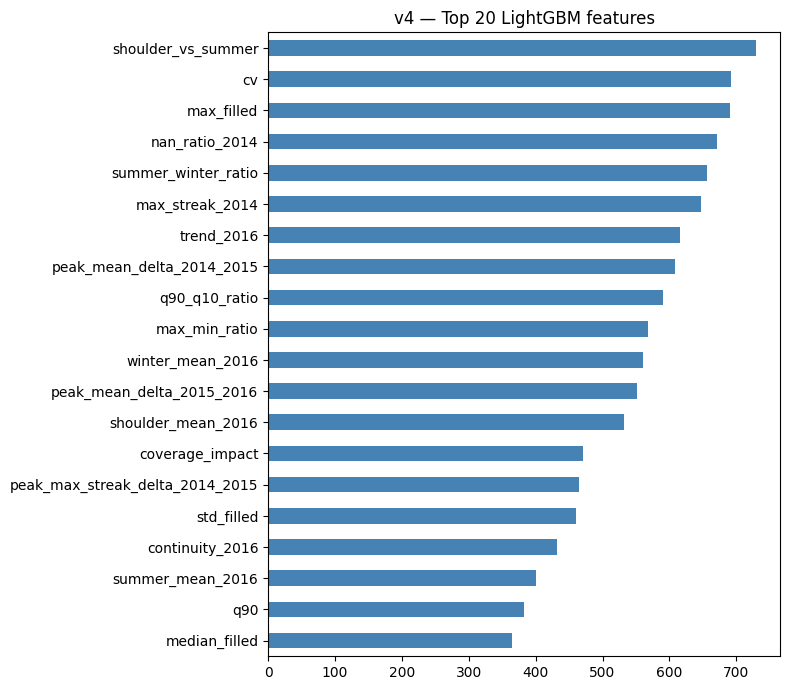


Saved: test_predictions_v4.parquet + feature_importance_v4.png


In [28]:
# ============================================================
# SGCC v4 Model
# ============================================================

import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

train = pd.read_parquet("/kaggle/working/features_train_v4.parquet")
test  = pd.read_parquet("/kaggle/working/features_test_v4.parquet")

feat_cols = [c for c in train.columns if c != "FLAG"]
print(f"Features: {len(feat_cols)}")

X_tr = train[feat_cols].values; y_tr = train["FLAG"].values
X_te = test[feat_cols].values;  y_te = test["FLAG"].values

print(f"Train: {X_tr.shape}  Test: {X_te.shape}")
print(f"Train theft: {y_tr.mean():.4f}  Test theft: {y_te.mean():.4f}")

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"scale_pos_weight: {spw:.2f}")

# Val split for threshold tuning
X_tr2, X_val, y_tr2, y_val = train_test_split(
    X_tr, y_tr, test_size=0.20, stratify=y_tr, random_state=42
)

# ============================================================
# LightGBM
# ============================================================
print("\n" + "="*60)
print("LightGBM (v4)")
print("="*60)

params_lgb = dict(
    n_estimators=500, num_leaves=31, learning_rate=0.05,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1,
    scale_pos_weight=spw, n_jobs=-1, random_state=42, verbose=-1,
)

m_val = lgb.LGBMClassifier(**params_lgb)
m_val.fit(X_tr2, y_tr2)
val_prob = m_val.predict_proba(X_val)[:, 1]

best_f1, best_thr = 0, 0.5
for thr in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(y_val, (val_prob >= thr).astype(int))
    if f1 > best_f1:
        best_f1, best_thr = f1, thr
print(f"Best threshold: {best_thr:.2f}  (val F1={best_f1:.4f})")

m_lgb = lgb.LGBMClassifier(**params_lgb)
m_lgb.fit(X_tr, y_tr)
prob_lgb = m_lgb.predict_proba(X_te)[:, 1]
pred_lgb = (prob_lgb >= best_thr).astype(int)

print(f"\nF1:        {f1_score(y_te, pred_lgb):.4f}")
print(f"Precision: {precision_score(y_te, pred_lgb):.4f}")
print(f"Recall:    {recall_score(y_te, pred_lgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_te, prob_lgb):.4f}")
print(f"AUC-PR:    {average_precision_score(y_te, prob_lgb):.4f}")
print(classification_report(y_te, pred_lgb, target_names=["Normal", "Theft"]))
print("Confusion matrix:")
print(confusion_matrix(y_te, pred_lgb))

# Feature importance
imp = pd.Series(m_lgb.feature_importances_, index=feat_cols).sort_values(ascending=False)
print("\nTop 20 LightGBM features:")
print(imp.head(20).to_string())

# ============================================================
# XGBoost
# ============================================================
print("\n" + "="*60)
print("XGBoost (v4)")
print("="*60)

params_xgb = dict(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0,
    scale_pos_weight=spw, tree_method="hist",
    n_jobs=-1, random_state=42, eval_metric="aucpr",
)

m_xgb_val = xgb.XGBClassifier(**params_xgb)
m_xgb_val.fit(X_tr2, y_tr2)
val_prob_x = m_xgb_val.predict_proba(X_val)[:, 1]

best_f1_x, best_thr_x = 0, 0.5
for thr in np.arange(0.05, 0.95, 0.01):
    f1 = f1_score(y_val, (val_prob_x >= thr).astype(int))
    if f1 > best_f1_x:
        best_f1_x, best_thr_x = f1, thr
print(f"Best threshold: {best_thr_x:.2f}  (val F1={best_f1_x:.4f})")

m_xgb = xgb.XGBClassifier(**params_xgb)
m_xgb.fit(X_tr, y_tr)
prob_xgb = m_xgb.predict_proba(X_te)[:, 1]
pred_xgb = (prob_xgb >= best_thr_x).astype(int)

print(f"\nF1:        {f1_score(y_te, pred_xgb):.4f}")
print(f"Precision: {precision_score(y_te, pred_xgb):.4f}")
print(f"Recall:    {recall_score(y_te, pred_xgb):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_te, prob_xgb):.4f}")
print(f"AUC-PR:    {average_precision_score(y_te, prob_xgb):.4f}")
print(classification_report(y_te, pred_xgb, target_names=["Normal", "Theft"]))

# ============================================================
# Summary
# ============================================================
print("\n" + "="*60)
print("SUMMARY v4")
print("="*60)
summary = pd.DataFrame({
    "Model":     ["LightGBM", "XGBoost"],
    "F1":        [f1_score(y_te, pred_lgb), f1_score(y_te, pred_xgb)],
    "Precision": [precision_score(y_te, pred_lgb), precision_score(y_te, pred_xgb)],
    "Recall":    [recall_score(y_te, pred_lgb), recall_score(y_te, pred_xgb)],
    "AUC-PR":    [average_precision_score(y_te, prob_lgb),
                  average_precision_score(y_te, prob_xgb)],
    "Threshold": [best_thr, best_thr_x],
})
print(summary.to_string(index=False))

# Save predictions
pd.DataFrame({
    "y_true": y_te,
    "prob_lgb": prob_lgb, "pred_lgb": pred_lgb,
    "prob_xgb": prob_xgb, "pred_xgb": pred_xgb,
}).to_parquet("/kaggle/working/test_predictions_v4.parquet")

# Feature importance plot
fig, ax = plt.subplots(figsize=(8, 7))
imp.head(20).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_title("v4 — Top 20 LightGBM features")
plt.tight_layout()
plt.savefig("/kaggle/working/feature_importance_v4.png", dpi=100)
plt.show()
print("\nSaved: test_predictions_v4.parquet + feature_importance_v4.png")

In [31]:
import pandas as pd
import numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns
             if c not in ("FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

# Peak months per year
peak = {
    yr: [c for c, d in zip(date_cols, dates) if d.year == yr and d.month in (6, 7, 8)]
    for yr in [2014, 2015, 2016]
}

# ---- Build the three new features per year ----
out = pd.DataFrame(index=df.index)
out["FLAG"] = df["FLAG"].values

for yr, cols in peak.items():
    sub = df[cols]
    med = sub.median(axis=1)
    mean = sub.mean(axis=1)

    out[f"peak_cv_{yr}"]   = sub.std(axis=1) / (mean + 1e-6)
    out[f"peak_skew_{yr}"] = sub.skew(axis=1)
    out[f"peak_days_above_2x_med_{yr}"] = sub.gt(2 * med, axis=0).sum(axis=1)
    out[f"peak_med_{yr}"]  = med
    out[f"peak_mean_{yr}"] = mean

# ---- Theft ratio by bucket ----
overall = out["FLAG"].mean()
print(f"Base theft ratio: {overall:.4f}\n")

def bucket_report(col, label, bins):
    print("=" * 68)
    print(f"{label}  ({col})")
    print("=" * 68)
    print(f"{'Bucket':<20} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 50)
    for lab, m in bins:
        n = m.sum()
        if n == 0:
            print(f"{lab:<20} {n:>8}")
            continue
        r = out.loc[m, "FLAG"].mean()
        print(f"{lab:<20} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")
    print()

# ---- CV analysis (main hypothesis) ----
for yr in [2014, 2015, 2016]:
    col = f"peak_cv_{yr}"
    q = out[col].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    bucket_report(col, f"{yr} PEAK CV (Jun-Aug volatility)", [
        (f"< Q10 ({q[0.1]:.2f})",  out[col] < q[0.1]),
        ("Q10-Q25",                 (out[col] >= q[0.1]) & (out[col] < q[0.25])),
        ("Q25-Q50",                 (out[col] >= q[0.25])& (out[col] < q[0.50])),
        ("Q50-Q75",                 (out[col] >= q[0.50])& (out[col] < q[0.75])),
        ("Q75-Q90",                 (out[col] >= q[0.75])& (out[col] < q[0.90])),
        (f"> Q90 ({q[0.9]:.2f})",  out[col] >= q[0.9]),
    ])

# ---- Skew analysis ----
for yr in [2016]:
    col = f"peak_skew_{yr}"
    q = out[col].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    bucket_report(col, f"{yr} PEAK SKEW (asymmetry of summer usage)", [
        (f"< Q10 ({q[0.1]:.2f})",  out[col] < q[0.1]),
        ("Q10-Q25",                 (out[col] >= q[0.1]) & (out[col] < q[0.25])),
        ("Q25-Q50",                 (out[col] >= q[0.25])& (out[col] < q[0.50])),
        ("Q50-Q75",                 (out[col] >= q[0.50])& (out[col] < q[0.75])),
        ("Q75-Q90",                 (out[col] >= q[0.75])& (out[col] < q[0.90])),
        (f"> Q90 ({q[0.9]:.2f})",  out[col] >= q[0.9]),
    ])

# ---- Days above 2x median ----
for yr in [2016]:
    col = f"peak_days_above_2x_med_{yr}"
    bucket_report(col, f"{yr} DAYS above 2x median (within peak)", [
        ("0",       out[col] == 0),
        ("1-2",     (out[col] >= 1) & (out[col] <= 2)),
        ("3-5",     (out[col] >= 3) & (out[col] <= 5)),
        ("6-10",    (out[col] >= 6) & (out[col] <= 10)),
        ("11-20",   (out[col] >= 11)& (out[col] <= 20)),
        (">20",     out[col] > 20),
    ])

# ---- Direct check: TP vs FP on these features ----
print("=" * 68)
print("Comparing theft vs honest on new features")
print("=" * 68)

theft = out[out["FLAG"] == 1]
norm  = out[out["FLAG"] == 0]

cols = [c for c in out.columns if c.startswith("peak_")]
comp = pd.DataFrame({
    "Theft mean":  theft[cols].mean(),
    "Normal mean": norm[cols].mean(),
    "Theft median":  theft[cols].median(),
    "Normal median": norm[cols].median(),
})
comp["diff_mean"] = comp["Theft mean"] - comp["Normal mean"]
comp = comp.round(3)
print(comp.to_string())

# Save for inspection
out.to_parquet("/kaggle/working/peak_volatility_features.parquet")
print("\nSaved: peak_volatility_features.parquet")

Base theft ratio: 0.0853

2014 PEAK CV (Jun-Aug volatility)  (peak_cv_2014)
Bucket                N users  Theft ratio     Lift
--------------------------------------------------
< Q10 (0.02)             2997       0.0380    0.45x
Q10-Q25                  4495       0.0768    0.90x
Q25-Q50                  7491       0.0833    0.98x
Q50-Q75                  7492       0.0845    0.99x
Q75-Q90                  4495       0.1063    1.25x
> Q90 (1.44)             2997       0.0971    1.14x

2015 PEAK CV (Jun-Aug volatility)  (peak_cv_2015)
Bucket                N users  Theft ratio     Lift
--------------------------------------------------
< Q10 (0.04)             2806       0.0321    0.38x
Q10-Q25                  4209       0.0715    0.84x
Q25-Q50                  7014       0.0737    0.86x
Q50-Q75                  7015       0.0746    0.87x
Q75-Q90                  4209       0.0912    1.07x
> Q90 (1.35)             2806       0.0670    0.79x

2016 PEAK CV (Jun-Aug volatility)  (peak_c

In [33]:
import pandas as pd
import numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

for yr in [2014, 2015, 2016]:
    cols = [c for c, d in zip(date_cols, dates) if d.year == yr and d.month in (6,7,8)]
    sub = df[cols]
    n_days = len(cols)

    # Three versions
    mean_filled = sub.mean(axis=1)             # skip NaN
    mean_total  = sub.sum(axis=1) / n_days     # NaN = 0
    # Ratio: user's peak_total vs their full-year baseline (NaN-aware)
    year_mean = df[date_cols].mean(axis=1)     # full year, skip NaN
    rel_spike_peak = mean_total / (year_mean + 1e-6)

    for name, vals in [("mean_filled", mean_filled),
                       ("mean_total",  mean_total),
                       ("rel_peak_total", rel_spike_peak)]:
        overall = df["FLAG"].mean()
        print(f"\n{'='*60}")
        print(f"{yr} — {name} — theft ratio")
        print(f"{'='*60}")
        q = vals.quantile([0.5, 0.75, 0.9, 0.95, 0.99])
        bins = [
            (f"< median ({q[0.5]:.2f})",  vals < q[0.5]),
            (f"median-Q75",                (vals >= q[0.5]) & (vals < q[0.75])),
            (f"Q75-Q90",                   (vals >= q[0.75]) & (vals < q[0.9])),
            (f"Q90-Q95",                   (vals >= q[0.9]) & (vals < q[0.95])),
            (f"Q95-Q99",                   (vals >= q[0.95]) & (vals < q[0.99])),
            (f"> Q99 ({q[0.99]:.2f})",    vals >= q[0.99]),
        ]
        print(f"{'Bucket':<20} {'N':>8} {'Theft':>10} {'Lift':>8}")
        for lab, m in bins:
            n = m.sum()
            if n == 0: continue
            r = df.loc[m, "FLAG"].mean()
            print(f"{lab:<20} {n:>8} {r:>10.4f} {r/overall:>7.2f}x")


2014 — mean_filled — theft ratio
Bucket                      N      Theft     Lift
< median (5.63)         15062     0.0687    0.81x
median-Q75               7531     0.0775    0.91x
Q75-Q90                  4519     0.0797    0.93x
Q90-Q95                  1506     0.1102    1.29x
Q95-Q99                  1205     0.1809    2.12x
> Q99 (78.21)             302     0.4106    4.81x

2014 — mean_total — theft ratio
Bucket                      N      Theft     Lift
< median (1.80)         21186     0.0770    0.90x
median-Q75              10593     0.0867    1.02x
Q75-Q90                  6354     0.0729    0.85x
Q90-Q95                  2120     0.0986    1.16x
Q95-Q99                  1695     0.1469    1.72x
> Q99 (56.51)             424     0.3420    4.01x

2014 — rel_peak_total — theft ratio
Bucket                      N      Theft     Lift
< median (0.67)         21183     0.1028    1.20x
median-Q75              10592     0.0749    0.88x
Q75-Q90                  6355     0.0582    0.

In [34]:
# ============================================================
# Interactive SGCC Visualizer — with year selector
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split

# ---------- Load ----------
df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

preds = pd.read_parquet("/kaggle/working/test_predictions_v4.parquet").reset_index(drop=True)

# ---------- Split (must match training) ----------
idx = np.arange(len(df))
idx_tr, idx_te, _, _ = train_test_split(
    idx, df["FLAG"].values, test_size=0.20,
    stratify=df["FLAG"].values, random_state=42
)

test_df = pd.DataFrame({
    "row_idx": idx_te,
    "y":       preds["y_true"].values,
    "prob":    preds["prob_lgb"].values,
    "pred":    preds["pred_lgb"].values,
})
test_df["group"] = "TN"
test_df.loc[(test_df.y == 1) & (test_df.pred == 1), "group"] = "TP"
test_df.loc[(test_df.y == 1) & (test_df.pred == 0), "group"] = "FN"
test_df.loc[(test_df.y == 0) & (test_df.pred == 1), "group"] = "FP"
test_df = test_df.reset_index(drop=True)

print("Group counts:")
print(test_df["group"].value_counts().to_string())

# ---------- Year column index maps ----------
years = ["2014", "2015", "2016"]
year_col_idx = {
    y: np.array([i for i, d in enumerate(dates) if str(d.year) == y])
    for y in years
}
year_col_idx["All"] = np.arange(len(dates))

# ---------- Max streak helper ----------
def max_streak_fn(nan_arr):
    if not nan_arr.any():
        return 0
    a = nan_arr.astype(int)
    d = np.diff(np.concatenate([[0], a, [0]]))
    s = np.where(d == 1)[0]
    e = np.where(d == -1)[0]
    return int((e - s).max())

# ---------- Precompute per-year stats ----------
# Structure: stats[year][row_idx] = dict
print("Precomputing per-year stats...")
stats = {y: {} for y in ["All"] + years}

for r in test_df["row_idx"]:
    vals_full = df.loc[r, date_cols].astype(float).values
    for y in ["All"] + years:
        idx_y = year_col_idx[y]
        vals_y = vals_full[idx_y]
        nan_y = np.isnan(vals_y)
        stats[y][r] = {
            "mean":       float(np.nanmean(vals_y)) if not np.all(nan_y) else 0.0,
            "nan_ratio":  float(nan_y.mean()),
            "max_streak": max_streak_fn(nan_y),
            "values":     vals_y,
            "nan_mask":   nan_y,
            "dates":      dates[idx_y],
        }
print("Done.")

# ---------- Widgets ----------
year_dd = widgets.Dropdown(
    options=["All", "2014", "2015", "2016"], value="All",
    description="Year:"
)
group_dd = widgets.Dropdown(
    options=["TP", "FN", "FP", "TN"], value="TP", description="Group:"
)
nan_dd = widgets.Dropdown(
    options=[
        ("Any", "any"), ("0%", "0"), ("0-10%", "0-10"),
        ("10-30%", "10-30"), ("30-50%", "30-50"),
        ("50-70%", "50-70"), (">70%", ">70"),
    ],
    value="any", description="NaN ratio:"
)
usage_dd = widgets.Dropdown(
    options=[
        ("Any", "any"), ("<5", "<5"), ("5-20", "5-20"),
        ("20-50", "20-50"), (">50", ">50"),
    ],
    value="any", description="Mean usage:"
)
streak_dd = widgets.Dropdown(
    options=[
        ("Any", "any"), ("0", "0"), ("1-7", "1-7"),
        ("7-30", "7-30"), ("30-90", "30-90"), (">90", ">90"),
    ],
    value="any", description="Max streak:"
)
n_show_slider = widgets.IntSlider(
    value=3, min=1, max=12, step=1, description="Show N:"
)
sort_dd = widgets.Dropdown(
    options=["random", "high_prob", "low_prob", "high_nan",
             "low_usage", "high_streak"],
    value="random", description="Sort by:"
)
run_btn = widgets.Button(description="Show", button_style="primary")
info_out = widgets.Output()
plot_out = widgets.Output()

# ---------- Filter ----------
def apply_filters():
    year = year_dd.value
    sub = test_df[test_df["group"] == group_dd.value].copy()
    if len(sub) == 0:
        return sub

    # Attach per-year stats
    sub["mean"]       = sub["row_idx"].map(lambda r: stats[year][r]["mean"])
    sub["nan_ratio"]  = sub["row_idx"].map(lambda r: stats[year][r]["nan_ratio"])
    sub["max_streak"] = sub["row_idx"].map(lambda r: stats[year][r]["max_streak"])

    v = nan_dd.value
    if v == "0":        sub = sub[sub.nan_ratio == 0]
    elif v == "0-10":   sub = sub[(sub.nan_ratio > 0)    & (sub.nan_ratio <= 0.10)]
    elif v == "10-30":  sub = sub[(sub.nan_ratio > 0.10) & (sub.nan_ratio <= 0.30)]
    elif v == "30-50":  sub = sub[(sub.nan_ratio > 0.30) & (sub.nan_ratio <= 0.50)]
    elif v == "50-70":  sub = sub[(sub.nan_ratio > 0.50) & (sub.nan_ratio <= 0.70)]
    elif v == ">70":    sub = sub[sub.nan_ratio > 0.70]

    v = usage_dd.value
    if v == "<5":       sub = sub[sub["mean"] < 5]
    elif v == "5-20":   sub = sub[(sub["mean"] >= 5)  & (sub["mean"] < 20)]
    elif v == "20-50":  sub = sub[(sub["mean"] >= 20) & (sub["mean"] < 50)]
    elif v == ">50":    sub = sub[sub["mean"] >= 50]

    v = streak_dd.value
    if v == "0":        sub = sub[sub.max_streak == 0]
    elif v == "1-7":    sub = sub[(sub.max_streak >= 1)  & (sub.max_streak <= 7)]
    elif v == "7-30":   sub = sub[(sub.max_streak > 7)   & (sub.max_streak <= 30)]
    elif v == "30-90":  sub = sub[(sub.max_streak > 30)  & (sub.max_streak <= 90)]
    elif v == ">90":    sub = sub[sub.max_streak > 90]

    s = sort_dd.value
    if s == "high_prob":      sub = sub.sort_values("prob", ascending=False)
    elif s == "low_prob":     sub = sub.sort_values("prob", ascending=True)
    elif s == "high_nan":     sub = sub.sort_values("nan_ratio", ascending=False)
    elif s == "low_usage":    sub = sub.sort_values("mean", ascending=True)
    elif s == "high_streak":  sub = sub.sort_values("max_streak", ascending=False)
    else:                     sub = sub.sample(frac=1).reset_index(drop=True)

    return sub

# ---------- Callback ----------
def on_show(b=None):
    info_out.clear_output(wait=False)
    plot_out.clear_output(wait=False)
    sub = apply_filters()
    year = year_dd.value

    with info_out:
        print(f"Year={year} | Group={group_dd.value} | NaN={nan_dd.value} | "
              f"Usage={usage_dd.value} | Streak={streak_dd.value} | Sort={sort_dd.value}")
        print(f"Qualifying: {len(sub)}  |  Showing: {min(n_show_slider.value, len(sub))}")
        if len(sub):
            print(f"Avg mean:      {sub['mean'].mean():.2f}")
            print(f"Avg NaN ratio: {sub['nan_ratio'].mean():.3f}")
            print(f"Avg streak:    {sub['max_streak'].mean():.1f}")
            print(f"Avg prob:      {sub['prob'].mean():.3f}")

    with plot_out:
        n = min(n_show_slider.value, len(sub))
        if n == 0:
            print("No users match filters.")
            return

        fig, axes = plt.subplots(n, 1, figsize=(14, 2.5 * n), sharex=False)
        if n == 1:
            axes = [axes]

        color = {"TP": "red", "FN": "orange", "FP": "blue", "TN": "green"}[group_dd.value]

        for i, (_, r) in enumerate(sub.head(n).iterrows()):
            s = stats[year][r["row_idx"]]
            d_plot = s["dates"]

            axes[i].plot(d_plot, s["values"], lw=0.5, color=color)
            axes[i].set_ylabel("Usage", fontsize=8)
            axes[i].set_title(
                f"{group_dd.value}  prob={r['prob']:.2f}  "
                f"mean={s['mean']:.2f}  NaN={s['nan_ratio']:.1%}  "
                f"streak={s['max_streak']}",
                fontsize=9
            )

            # Shade NaN
            nm = s["nan_mask"]
            if nm.any():
                d = np.diff(np.concatenate([[0], nm.astype(int), [0]]))
                starts = np.where(d == 1)[0]
                ends   = np.where(d == -1)[0]
                for st, en in zip(starts, ends):
                    st = min(st, len(d_plot) - 1)
                    en = min(en, len(d_plot) - 1)
                    if st <= en:
                        axes[i].axvspan(d_plot[st], d_plot[en],
                                        color="gray", alpha=0.35)

        axes[-1].set_xlabel("Date")
        plt.tight_layout()
        plt.show()

# ---------- Bind ----------
for w in [year_dd, group_dd, nan_dd, usage_dd, streak_dd, sort_dd, n_show_slider]:
    w.observe(on_show, names="value")
run_btn.on_click(on_show)

# ---------- Layout ----------
ui = widgets.VBox([
    widgets.HBox([year_dd, group_dd, nan_dd]),
    widgets.HBox([usage_dd, streak_dd]),
    widgets.HBox([n_show_slider, sort_dd, run_btn]),
    info_out,
])
display(ui)
display(plot_out)

on_show(None)

Group counts:
group
TN    7321
FP     431
TP     373
FN     350
Precomputing per-year stats...
Done.


Output()

In [37]:
# ============================================================
# Flatness EDA v2 — exclude zeros, apply 5% tolerance
# ============================================================

import pandas as pd
import numpy as np

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")

cols_2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
print(f"2016 cols: {len(cols_2016)}")

# ============================================================
# Flatness functions
# ============================================================
def flat_exact(v):
    """Exact equality with previous non-NaN value."""
    v = v[~np.isnan(v)]
    if len(v) < 2:
        return 0, 0
    equal = (v[1:] == v[:-1])
    return int(equal.sum()), len(equal)

def flat_nonzero(v):
    """Exact equality, excluding zeros."""
    v = v[~np.isnan(v)]
    v = v[v > 0]
    if len(v) < 2:
        return 0, 0
    equal = (v[1:] == v[:-1])
    return int(equal.sum()), len(equal)

def flat_tolerance(v, tol=0.05):
    """Near-flat: relative change < tol, excluding zeros."""
    v = v[~np.isnan(v)]
    v = v[v > 0]
    if len(v) < 2:
        return 0, 0
    rel = np.abs(np.diff(v)) / (v[:-1] + 1e-6)
    near = (rel < tol)
    return int(near.sum()), len(near)

def flat_tolerance_1pct(v):
    """Strict near-flat: 1% tolerance."""
    return flat_tolerance(v, tol=0.01)

def flat_tolerance_10pct(v):
    """Loose near-flat: 10% tolerance."""
    return flat_tolerance(v, tol=0.10)

# ============================================================
# Compute all variants in one pass
# ============================================================
N = len(df)
results = {
    "flat_exact_count":      np.zeros(N, dtype=int),
    "flat_nonzero_count":    np.zeros(N, dtype=int),
    "flat_1pct_count":       np.zeros(N, dtype=int),
    "flat_5pct_count":       np.zeros(N, dtype=int),
    "flat_10pct_count":      np.zeros(N, dtype=int),
    "valid_exact":           np.zeros(N, dtype=int),
    "valid_nonzero":         np.zeros(N, dtype=int),
    "zero_days_2016":        np.zeros(N, dtype=int),
}

print("Computing flatness variants...")
for i, (_, row) in enumerate(df[cols_2016].iterrows()):
    v = row.values.astype(float)

    # Exact
    c, t = flat_exact(v)
    results["flat_exact_count"][i] = c
    results["valid_exact"][i] = t

    # Nonzero exact
    c, t = flat_nonzero(v)
    results["flat_nonzero_count"][i] = c
    results["valid_nonzero"][i] = t

    # Tolerances
    results["flat_1pct_count"][i]  = flat_tolerance_1pct(v)[0]
    results["flat_5pct_count"][i]  = flat_tolerance(v, 0.05)[0]
    results["flat_10pct_count"][i] = flat_tolerance(v, 0.10)[0]

    # Zero days
    results["zero_days_2016"][i] = int((v == 0).sum())

for k, v in results.items():
    df[k] = v

# Ratios
df["flat_exact_ratio"]   = df["flat_exact_count"]   / (df["valid_exact"]   + 1e-6)
df["flat_nonzero_ratio"] = df["flat_nonzero_count"] / (df["valid_nonzero"] + 1e-6)

# ============================================================
# Bucket analysis for each variant
# ============================================================
overall = df["FLAG"].mean()
print(f"\nBase theft ratio: {overall:.4f}")

def bucket_report(col, label, bins):
    print(f"\n{'='*72}")
    print(f"{label}  ({col})")
    print(f"{'='*72}")
    print(f"{'Bucket':<20} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 52)
    for lab, m in bins:
        n = m.sum()
        if n == 0:
            continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<20} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# ---- 1. flat_nonzero_count (main candidate) ----
bucket_report(
    "flat_nonzero_count",
    "2016 — FLAT NONZERO count (exclude zeros, exact equality)",
    [
        ("0",          df["flat_nonzero_count"] == 0),
        ("1-5",        (df["flat_nonzero_count"] >= 1)  & (df["flat_nonzero_count"] <= 5)),
        ("6-20",       (df["flat_nonzero_count"] >= 6)  & (df["flat_nonzero_count"] <= 20)),
        ("21-50",      (df["flat_nonzero_count"] >= 21) & (df["flat_nonzero_count"] <= 50)),
        ("51-100",     (df["flat_nonzero_count"] >= 51) & (df["flat_nonzero_count"] <= 100)),
        ("101-200",    (df["flat_nonzero_count"] >= 101)& (df["flat_nonzero_count"] <= 200)),
        (">200",       df["flat_nonzero_count"] > 200),
    ]
)

# ---- 2. flat_5pct_count ----
bucket_report(
    "flat_5pct_count",
    "2016 — FLAT 5% tolerance count (near-constant days)",
    [
        ("0",          df["flat_5pct_count"] == 0),
        ("1-5",        (df["flat_5pct_count"] >= 1)  & (df["flat_5pct_count"] <= 5)),
        ("6-20",       (df["flat_5pct_count"] >= 6)  & (df["flat_5pct_count"] <= 20)),
        ("21-50",      (df["flat_5pct_count"] >= 21) & (df["flat_5pct_count"] <= 50)),
        ("51-100",     (df["flat_5pct_count"] >= 51) & (df["flat_5pct_count"] <= 100)),
        ("101-200",    (df["flat_5pct_count"] >= 101)& (df["flat_5pct_count"] <= 200)),
        (">200",       df["flat_5pct_count"] > 200),
    ]
)

# ---- 3. flat_10pct_count ----
bucket_report(
    "flat_10pct_count",
    "2016 — FLAT 10% tolerance count",
    [
        ("0",          df["flat_10pct_count"] == 0),
        ("1-5",        (df["flat_10pct_count"] >= 1)  & (df["flat_10pct_count"] <= 5)),
        ("6-20",       (df["flat_10pct_count"] >= 6)  & (df["flat_10pct_count"] <= 20)),
        ("21-50",      (df["flat_10pct_count"] >= 21) & (df["flat_10pct_count"] <= 50)),
        ("51-100",     (df["flat_10pct_count"] >= 51) & (df["flat_10pct_count"] <= 100)),
        ("101-200",    (df["flat_10pct_count"] >= 101)& (df["flat_10pct_count"] <= 200)),
        (">200",       df["flat_10pct_count"] > 200),
    ]
)

# ---- 4. flat_nonzero_ratio ----
q = df["flat_nonzero_ratio"].quantile([0.25, 0.5, 0.75, 0.9, 0.95])
bucket_report(
    "flat_nonzero_ratio",
    "2016 — FLAT NONZERO ratio (flat count / valid nonzero days)",
    [
        (f"< Q25 ({q[0.25]:.2f})",  df["flat_nonzero_ratio"] < q[0.25]),
        (f"Q25-Q50",                (df["flat_nonzero_ratio"] >= q[0.25]) & (df["flat_nonzero_ratio"] < q[0.5])),
        (f"Q50-Q75",                (df["flat_nonzero_ratio"] >= q[0.5])  & (df["flat_nonzero_ratio"] < q[0.75])),
        (f"Q75-Q90",                (df["flat_nonzero_ratio"] >= q[0.75]) & (df["flat_nonzero_ratio"] < q[0.9])),
        (f"Q90-Q95",                (df["flat_nonzero_ratio"] >= q[0.9])  & (df["flat_nonzero_ratio"] < q[0.95])),
        (f"> Q95 ({q[0.95]:.2f})",  df["flat_nonzero_ratio"] >= q[0.95]),
    ]
)

# ============================================================
# Direct comparison: Thief vs Honest
# ============================================================
print(f"\n{'='*72}")
print("Thief vs Honest — flat statistics")
print(f"{'='*72}")
th = df[df["FLAG"] == 1]
hn = df[df["FLAG"] == 0]
cols_compare = ["flat_exact_count", "flat_nonzero_count", "flat_1pct_count",
                "flat_5pct_count", "flat_10pct_count", "flat_nonzero_ratio"]
print(f"{'Feature':<22} {'Theft mean':>12} {'Honest mean':>12} {'Diff':>10}")
print("-" * 60)
for c in cols_compare:
    tm = th[c].mean()
    hm = hn[c].mean()
    print(f"{c:<22} {tm:>12.3f} {hm:>12.3f} {tm-hm:>+10.3f}")

# ============================================================
# Zero-day cross-tab (to understand contamination)
# ============================================================
print(f"\n{'='*72}")
print("Theft ratio by ZERO DAYS bucket (2016)")
print(f"{'='*72}")
print(f"{'Zero days':<14} {'N':>8} {'Theft ratio':>12} {'Lift':>8}")
print("-" * 46)
for lab, m in [
    ("0",           df["zero_days_2016"] == 0),
    ("1-10",        (df["zero_days_2016"] >= 1)   & (df["zero_days_2016"] <= 10)),
    ("11-50",       (df["zero_days_2016"] >= 11)  & (df["zero_days_2016"] <= 50)),
    ("51-100",      (df["zero_days_2016"] >= 51)  & (df["zero_days_2016"] <= 100)),
    ("101-200",     (df["zero_days_2016"] >= 101) & (df["zero_days_2016"] <= 200)),
    (">200",        df["zero_days_2016"] > 200),
]:
    n = m.sum()
    if n == 0:
        continue
    r = df.loc[m, "FLAG"].mean()
    print(f"{lab:<14} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# ============================================================
# Save
# ============================================================
save_cols = ["FLAG", "zero_days_2016",
             "flat_exact_count", "flat_nonzero_count",
             "flat_1pct_count", "flat_5pct_count", "flat_10pct_count",
             "flat_nonzero_ratio"]
df[save_cols].to_parquet("/kaggle/working/flat_features_v2.parquet")
print("\nSaved: flat_features_v2.parquet")

2016 cols: 304
Computing flatness variants...

Base theft ratio: 0.0853

2016 — FLAT NONZERO count (exclude zeros, exact equality)  (flat_nonzero_count)
Bucket                N users  Theft ratio     Lift
----------------------------------------------------
0                       17283       0.1063    1.25x
1-5                     18182       0.0799    0.94x
6-20                     4126       0.0499    0.59x
21-50                    1669       0.0485    0.57x
51-100                    682       0.0367    0.43x
101-200                   420       0.0262    0.31x
>200                       10       0.2000    2.34x

2016 — FLAT 5% tolerance count (near-constant days)  (flat_5pct_count)
Bucket                N users  Theft ratio     Lift
----------------------------------------------------
0                        3820       0.0353    0.41x
1-5                      1355       0.0546    0.64x
6-20                     2648       0.0819    0.96x
21-50                   16630       0.0898   

In [41]:
# ============================================================
# Shape features EDA — fixed (no warning flood, progress prints)
# ============================================================
import warnings
warnings.filterwarnings("ignore")   # suppress all warnings

import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# ---------- Load ----------
df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG", "missing_count", "missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")
cols_2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
print(f"Using {len(cols_2016)} days from 2016")

# ============================================================
# Shape feature functions — all NaN-aware and constant-safe
# ============================================================
def acf(series, lag):
    s = series.dropna()
    if len(s) < lag + 5:
        return np.nan
    if s.std() < 1e-9:
        return np.nan
    try:
        v = s.autocorr(lag=lag)
        return float(v) if not np.isnan(v) else np.nan
    except Exception:
        return np.nan


def rolling_std_stats(series, window=7):
    s = series.dropna()
    if len(s) < window + 5:
        return np.nan, np.nan, np.nan
    r = s.rolling(window).std().dropna()
    if len(r) == 0:
        return np.nan, np.nan, np.nan
    return float(r.mean()), float(r.max()), float(r.std())


def flat_streak_max(series, tol=0.05):
    v = series.dropna().values
    if len(v) < 2:
        return 0
    prev, curr = v[:-1], v[1:]
    with np.errstate(divide='ignore', invalid='ignore'):
        rel = np.abs(curr - prev) / (prev + 1e-6)
    rel = np.where(prev == 0, np.where(curr == 0, 0, 1), rel)
    flat = rel < tol
    max_run = cur = 0
    for f in flat:
        cur = cur + 1 if f else 0
        if cur > max_run:
            max_run = cur
    return int(max_run)


def spike_count(series, mult=3.0):
    s = series.dropna()
    if len(s) < 10:
        return 0
    roll_med = s.rolling(7, min_periods=3).median()
    spikes = (s > mult * roll_med).sum()
    return int(spikes)


def max_drawdown(series):
    v = series.dropna().values
    if len(v) < 5:
        return 0.0
    running_max = np.maximum.accumulate(v)
    with np.errstate(divide='ignore', invalid='ignore'):
        dd = (v - running_max) / (running_max + 1e-6)
    dd = dd[~np.isnan(dd)]
    return float(dd.min()) if len(dd) else 0.0


def zero_crossings(series):
    v = series.dropna().values
    if len(v) < 5:
        return 0
    med = np.median(v)
    signs = np.sign(v - med)
    signs = signs[signs != 0]
    if len(signs) < 2:
        return 0
    return int((np.diff(signs) != 0).sum())


# ============================================================
# Compute per-user (with progress prints)
# ============================================================
print("Computing shape features...")

FEAT_NAMES = ["acf_lag1", "acf_lag7", "acf_lag14", "acf_lag30",
              "roll7_std_mean", "roll7_std_max", "roll7_std_std",
              "flat_streak_max", "spike_count_3x", "spike_count_5x",
              "max_drawdown", "zero_crossings"]

user_shape = []
total = len(df)

for i, (_, row) in enumerate(df[cols_2016].iterrows()):
    if i % 5000 == 0:
        print(f"  {i} / {total}")

    s = row.astype(float)

    try:
        f = {
            "acf_lag1":        acf(s, 1),
            "acf_lag7":        acf(s, 7),
            "acf_lag14":       acf(s, 14),
            "acf_lag30":       acf(s, 30),
            "roll7_std_mean":  rolling_std_stats(s, 7)[0],
            "roll7_std_max":   rolling_std_stats(s, 7)[1],
            "roll7_std_std":   rolling_std_stats(s, 7)[2],
            "flat_streak_max": flat_streak_max(s),
            "spike_count_3x":  spike_count(s, 3.0),
            "spike_count_5x":  spike_count(s, 5.0),
            "max_drawdown":    max_drawdown(s),
            "zero_crossings":  zero_crossings(s),
        }
    except Exception as e:
        # Fallback — all NaN
        f = {c: np.nan for c in FEAT_NAMES}
        if i % 1000 == 0:
            print(f"  row {i} failed: {e}")

    user_shape.append(f)

print(f"  {total} / {total} — done")

shape_df = pd.DataFrame(user_shape)
for c in FEAT_NAMES:
    df[c] = shape_df[c].values

print(f"\nNaN counts per shape feature:")
print(shape_df.isna().sum().to_string())

# ============================================================
# Thief vs Honest comparison (with Cohen's d)
# ============================================================
print("\n" + "="*78)
print("Shape features: thief vs honest")
print("="*78)
th = df[df["FLAG"] == 1]
hn = df[df["FLAG"] == 0]

print(f"{'Feature':<20} {'Theft mean':>12} {'Honest mean':>12} "
      f"{'Diff':>10} {'Cohen d':>10}")
print("-" * 70)
for c in FEAT_NAMES:
    tm = th[c].mean()
    hm = hn[c].mean()
    ts = th[c].std()
    hs = hn[c].std()
    pooled = np.sqrt((ts**2 + hs**2) / 2 + 1e-9)
    effect = (tm - hm) / pooled
    print(f"{c:<20} {tm:>12.4f} {hm:>12.4f} {tm-hm:>+10.4f} {effect:>+10.3f}")

# ============================================================
# Bucket analysis (lift per quantile)
# ============================================================
overall = df["FLAG"].mean()
print(f"\nBase theft ratio: {overall:.4f}")

def bucket_report(col, label):
    q = df[col].quantile([0.2, 0.4, 0.6, 0.8, 0.9, 0.95])
    print(f"\n{'='*72}")
    print(f"{label}  ({col})")
    print(f"{'='*72}")
    print(f"{'Bucket':<18} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 50)
    bins = [
        (f"< Q20",   df[col] < q[0.2]),
        (f"Q20-Q40", (df[col] >= q[0.2]) & (df[col] < q[0.4])),
        (f"Q40-Q60", (df[col] >= q[0.4]) & (df[col] < q[0.6])),
        (f"Q60-Q80", (df[col] >= q[0.6]) & (df[col] < q[0.8])),
        (f"Q80-Q90", (df[col] >= q[0.8]) & (df[col] < q[0.9])),
        (f"Q90-Q95", (df[col] >= q[0.9]) & (df[col] < q[0.95])),
        (f"> Q95",   df[col] >= q[0.95]),
    ]
    for lab, m in bins:
        n = m.sum()
        if n == 0:
            continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<18} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

for c in FEAT_NAMES:
    bucket_report(c, c)

# ============================================================
# Correlation with existing strong features
# ============================================================
print("\n" + "="*78)
print("Correlation with existing strong features")
print("="*78)

# Compute a few baseline features for correlation
base = {}
base["mean_filled"] = df[cols_2016].mean(axis=1)
base["nan_ratio"]   = df[cols_2016].isna().mean(axis=1)
base["max_filled"]  = df[cols_2016].max(axis=1)
base["cv"]          = df[cols_2016].std(axis=1) / (base["mean_filled"] + 1e-6)
base["std_filled"]  = df[cols_2016].std(axis=1)

print(f"\n{'Shape feature':<22} " + " ".join(f"{k:>14}" for k in base))
print("-" * (22 + 15 * len(base)))
for c in FEAT_NAMES:
    row_str = f"{c:<22} "
    for k, v in base.items():
        mask = df[c].notna() & v.notna()
        if mask.sum() > 100:
            try:
                r, _ = pearsonr(df.loc[mask, c], v[mask])
                row_str += f"{r:>+14.3f} "
            except Exception:
                row_str += f"{'nan':>14} "
        else:
            row_str += f"{'nan':>14} "
    print(row_str)

# ============================================================
# Save
# ============================================================
save_cols = ["FLAG"] + FEAT_NAMES
df[save_cols].to_parquet("/kaggle/working/shape_features.parquet")
print("\nSaved: shape_features.parquet")

Using 304 days from 2016
Computing shape features...
  0 / 42372
  5000 / 42372
  10000 / 42372
  15000 / 42372
  20000 / 42372
  25000 / 42372
  30000 / 42372
  35000 / 42372
  40000 / 42372
  42372 / 42372 — done

NaN counts per shape feature:
acf_lag1           2983
acf_lag7           3009
acf_lag14          3053
acf_lag30          3177
roll7_std_mean       52
roll7_std_max        52
roll7_std_std        52
flat_streak_max       0
spike_count_3x        0
spike_count_5x        0
max_drawdown          0
zero_crossings        0

Shape features: thief vs honest
Feature                Theft mean  Honest mean       Diff    Cohen d
----------------------------------------------------------------------
acf_lag1                   0.7286       0.6571    +0.0716     +0.338
acf_lag7                   0.4760       0.4217    +0.0543     +0.230
acf_lag14                  0.3705       0.3272    +0.0434     +0.181
acf_lag30                  0.2350       0.1935    +0.0415     +0.184
roll7_std_mean   

In [42]:
# ============================================================
# Extended autocorrelation features — lags 1, 7, 14, 30, 45, 60
# ============================================================
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

df = pd.read_parquet("/kaggle/working/cleaned_sgcc.parquet").reset_index()
if "CONS_NO" in df.columns:
    df = df.drop(columns=["CONS_NO"])

date_cols = [c for c in df.columns if c not in ("FLAG","missing_count","missing_ratio")]
dates = pd.to_datetime(date_cols, format="%m/%d/%Y")
cols_2016 = [c for c, d in zip(date_cols, dates) if d.year == 2016]
print(f"Using {len(cols_2016)} days from 2016")

# ---------- ACF helper ----------
def acf(series, lag, min_pairs=30):
    """Autocorrelation at given lag. NaN-safe. Returns NaN if too few pairs."""
    s = series.dropna()
    if len(s) < lag + min_pairs:
        return np.nan
    if s.std() < 1e-9:
        return np.nan
    try:
        v = s.autocorr(lag=lag)
        return float(v) if not np.isnan(v) else np.nan
    except Exception:
        return np.nan

# ---------- Compute per user ----------
LAGS = [1, 7, 14, 30, 45, 60]

print("Computing autocorrelation features...")
acf_values = {f"acf_lag{l}": [] for l in LAGS}

for i, (_, row) in enumerate(df[cols_2016].iterrows()):
    if i % 10000 == 0:
        print(f"  {i} / {len(df)}")
    s = row.astype(float)
    for lag in LAGS:
        acf_values[f"acf_lag{lag}"].append(acf(s, lag))

for k, v in acf_values.items():
    df[k] = v

# ---------- Non-NaN counts ----------
print("\nNaN counts per lag:")
for lag in LAGS:
    col = f"acf_lag{lag}"
    n_nan = df[col].isna().sum()
    print(f"  {col}: {n_nan} NaN ({100*n_nan/len(df):.1f}%)")

# ---------- Thief vs Honest comparison ----------
print("\n" + "="*78)
print("Autocorrelation at various lags: thief vs honest")
print("="*78)
th = df[df["FLAG"] == 1]
hn = df[df["FLAG"] == 0]

print(f"{'Feature':<14} {'Theft mean':>12} {'Honest mean':>12} "
      f"{'Diff':>10} {'Cohen d':>10} {'Q95 lift':>10}")
print("-" * 72)

overall = df["FLAG"].mean()

for lag in LAGS:
    col = f"acf_lag{lag}"
    tm = th[col].mean()
    hm = hn[col].mean()
    ts = th[col].std()
    hs = hn[col].std()
    pooled = np.sqrt((ts**2 + hs**2) / 2 + 1e-9)
    d = (tm - hm) / pooled

    # Q95 lift
    q95 = df[col].quantile(0.95)
    hi = df[df[col] >= q95]
    lift_hi = hi["FLAG"].mean() / overall

    print(f"{col:<14} {tm:>12.4f} {hm:>12.4f} {tm-hm:>+10.4f} "
          f"{d:>+10.3f} {lift_hi:>10.2f}x")

# ---------- Bucket tables per lag ----------
print(f"\nBase theft ratio: {overall:.4f}")

for lag in LAGS:
    col = f"acf_lag{lag}"
    q = df[col].quantile([0.2, 0.4, 0.6, 0.8, 0.9, 0.95])
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(f"{'Bucket':<12} {'N users':>8} {'Theft ratio':>12} {'Lift':>8}")
    print("-" * 44)
    for lab, m in [
        ("< Q20",   df[col] < q[0.2]),
        ("Q20-Q40", (df[col] >= q[0.2]) & (df[col] < q[0.4])),
        ("Q40-Q60", (df[col] >= q[0.4]) & (df[col] < q[0.6])),
        ("Q60-Q80", (df[col] >= q[0.6]) & (df[col] < q[0.8])),
        ("Q80-Q90", (df[col] >= q[0.8]) & (df[col] < q[0.9])),
        ("Q90-Q95", (df[col] >= q[0.9]) & (df[col] < q[0.95])),
        ("> Q95",   df[col] >= q[0.95]),
    ]:
        n = m.sum()
        if n == 0:
            continue
        r = df.loc[m, "FLAG"].mean()
        print(f"{lab:<12} {n:>8} {r:>12.4f} {r/overall:>7.2f}x")

# ---------- Correlation among lags ----------
print(f"\n{'='*60}")
print("Correlation between lags (are they redundant?)")
print(f"{'='*60}")
lag_cols = [f"acf_lag{l}" for l in LAGS]
corr = df[lag_cols].corr().round(3)
print(corr.to_string())

# ---------- Save ----------
save_cols = ["FLAG"] + lag_cols
df[save_cols].to_parquet("/kaggle/working/acf_features.parquet")
print(f"\nSaved: acf_features.parquet")

Using 304 days from 2016
Computing autocorrelation features...
  0 / 42372
  10000 / 42372
  20000 / 42372
  30000 / 42372
  40000 / 42372

NaN counts per lag:
  acf_lag1: 2989 NaN (7.1%)
  acf_lag7: 3021 NaN (7.1%)
  acf_lag14: 3069 NaN (7.2%)
  acf_lag30: 3192 NaN (7.5%)
  acf_lag45: 3352 NaN (7.9%)
  acf_lag60: 3532 NaN (8.3%)

Autocorrelation at various lags: thief vs honest
Feature          Theft mean  Honest mean       Diff    Cohen d   Q95 lift
------------------------------------------------------------------------
acf_lag1             0.7289       0.6571    +0.0718     +0.340       1.75x
acf_lag7             0.4767       0.4218    +0.0549     +0.234       1.49x
acf_lag14            0.3708       0.3273    +0.0435     +0.182       1.51x
acf_lag30            0.2351       0.1936    +0.0416     +0.184       1.48x
acf_lag45            0.1035       0.0773    +0.0263     +0.130       1.25x
acf_lag60            0.0298       0.0088    +0.0209     +0.101       1.26x

Base theft ratio: 0.